
# CA5 - Amazon Food Reviews Clustering Project


### Amir Parsa Mobed
### student ID: 810100271


## 1) Setup and Reproducibility


In [ ]:

#!pip install -q sentence-transformers huggingface_hub umap-learn scikit-learn pandas matplotlib seaborn tqdm nltk

import os
import re
import json
import random
import warnings
import unicodedata
import time
from collections import Counter
from dataclasses import dataclass
from typing import Callable, Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, homogeneity_score

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_PATH = "./amazon_reviews.csv"
STOPWORDS_PATH = "./stopwords-en.txt"



def load_stopwords(path: str) -> set:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Stopwords file not found: {path}")
    with open(path, "r", encoding="utf-8") as f:
        return {line.strip().lower() for line in f if line.strip()}


# In-memory cache for embeddings to avoid repeated expensive encoding
EMBEDDING_CACHE: Dict[tuple, np.ndarray] = {}


## 2) Load and Parse Raw Dataset

In [16]:

raw_df = pd.read_csv(DATA_PATH)
print("Raw shape:", raw_df.shape)
raw_df.head(3)


Raw shape: (2732, 1)


,raw_data
0,Id: 329849\nUserId: A1YZYHCKDK2K4I\nProfileNam...
1,Id: 329946\nUserId: A1JSXH2JWFMOU4\nProfileNam...
2,Id: 563717\nUserId: A13VH0PS4SKVDF\nProfileNam...


In [17]:

# Each raw_data row contains lines like "Field: value". This function parses them into a dictionary.
def parse_raw_record(raw_text: str) -> Dict[str, str]:
    fields = {
        "Id": None,
        "UserId": None,
        "ProfileName": None,
        "HelpfulnessNumerator": None,
        "HelpfulnessDenominator": None,
        "Score": None,
        "Time": None,
        "Summary": None,
        "Text": None,
    }

    if not isinstance(raw_text, str):
        return fields

    lines = raw_text.split("\n")
    current_key = None
    for line in lines:
        if ":" in line:
            key, value = line.split(":", 1)
            key = key.strip()
            value = value.strip()
            if key in fields:
                fields[key] = value
                current_key = key
            else:
                current_key = None
        else:
            # If the next line continues the previous field value (rare case)
            if current_key is not None and fields[current_key] is not None:
                fields[current_key] += " " + line.strip()

    return fields

parsed = [parse_raw_record(x) for x in tqdm(raw_df["raw_data"], desc="Parsing records")]
df = pd.DataFrame(parsed)

# Convert column types
num_cols = ["Id", "HelpfulnessNumerator", "HelpfulnessDenominator", "Score", "Time"]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["datetime"] = pd.to_datetime(df["Time"], unit="s", errors="coerce")

# Drop records without main text
df = df.dropna(subset=["Text"]).reset_index(drop=True)

print("Parsed shape:", df.shape)
print(df.dtypes)
df.head(3)


Parsing records:   0%|          | 0/2732 [00:00<?, ?it/s]

Parsed shape: (2732, 10)
Id                                 int64
UserId                            object
ProfileName                       object
HelpfulnessNumerator               int64
HelpfulnessDenominator             int64
Score                              int64
Time                               int64
Summary                           object
Text                              object
datetime                  datetime64[ns]
dtype: object


,Id,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,datetime
0,329849,A1YZYHCKDK2K4I,Santorini,2,2,5,1328832000,My Pooch loves them,Since my pet does not like having his teeth cl...,2012-02-10
1,329946,A1JSXH2JWFMOU4,"Lynw21 ""Lyn""",1,2,5,1314144000,great product,I was amazed at how well these cleaned my dogs...,2011-08-24
2,563717,A13VH0PS4SKVDF,Karen,0,0,5,1341792000,Quaker soft baked oatmeal cookie,I rec'd this product from influenster and Quak...,2012-07-09


## 3) Initial EDA and Some Visualizations

In [18]:

print("Sample records:")
display(df[["Id", "UserId", "Score", "Summary", "Text"]].sample(5, random_state=RANDOM_STATE))


Sample records:


,Id,UserId,Score,Summary,Text
1000,563062,A2Q53HT28RCH8N,4,Moist and delish,The Quaker Soft Baked Oatmeal Cookie was given...
1097,31131,A5LQNB1ZPDO5I,5,great chips,Best chips I've ever eaten but you should sell...
2565,563793,A2ZQODD5XZVSM9,5,So yummy!,"I don't like raisins to be completely honest, ..."
942,563741,A1MKFNZSI1EISM,5,Tasty and Nutritious!,I didn't expect a lot from a pre-packaged cook...
73,329689,AKWP7LOOOF3NB,4,Tasty treats,My dog is relatively picky when it comes to tr...


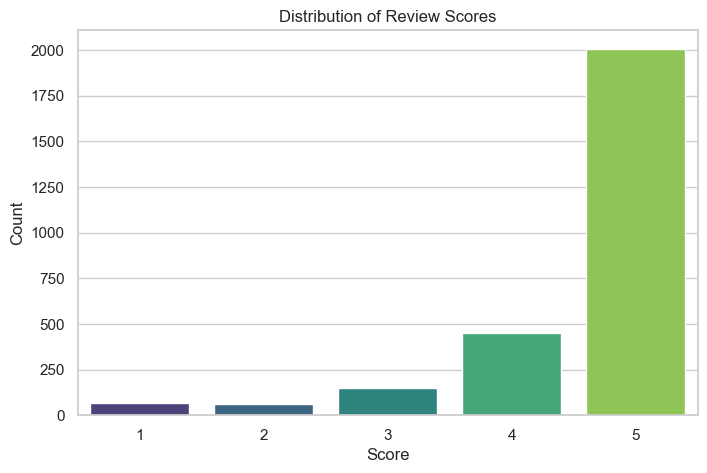

In [19]:

# Histogram of Score
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Score", palette="viridis")
plt.title("Distribution of Review Scores")
plt.xlabel("Score")
plt.ylabel("Count")
plt.show()


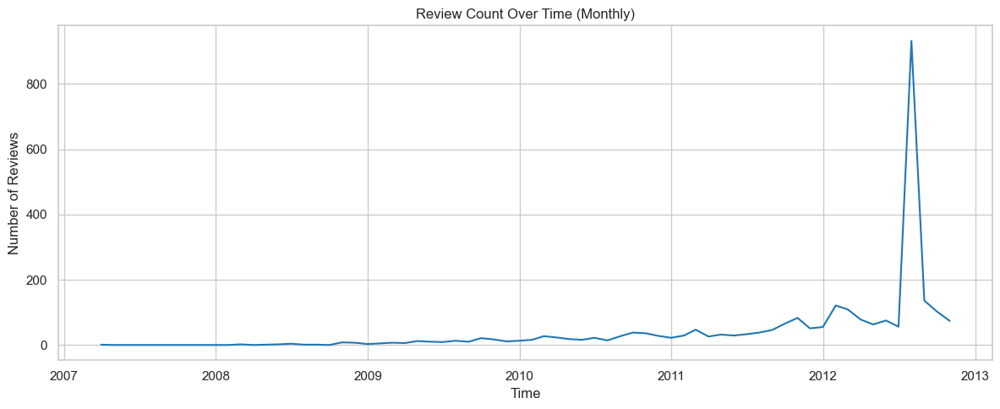

In [20]:

# Distribution of reviews over time
reviews_per_month = (
    df.set_index("datetime")
      .resample("M")
      .size()
      .rename("count")
      .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(reviews_per_month["datetime"], reviews_per_month["count"], color="tab:blue")
plt.title("Review Count Over Time (Monthly)")
plt.xlabel("Time")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


Tokenizing for top words:   0%|          | 0/2732 [00:00<?, ?it/s]

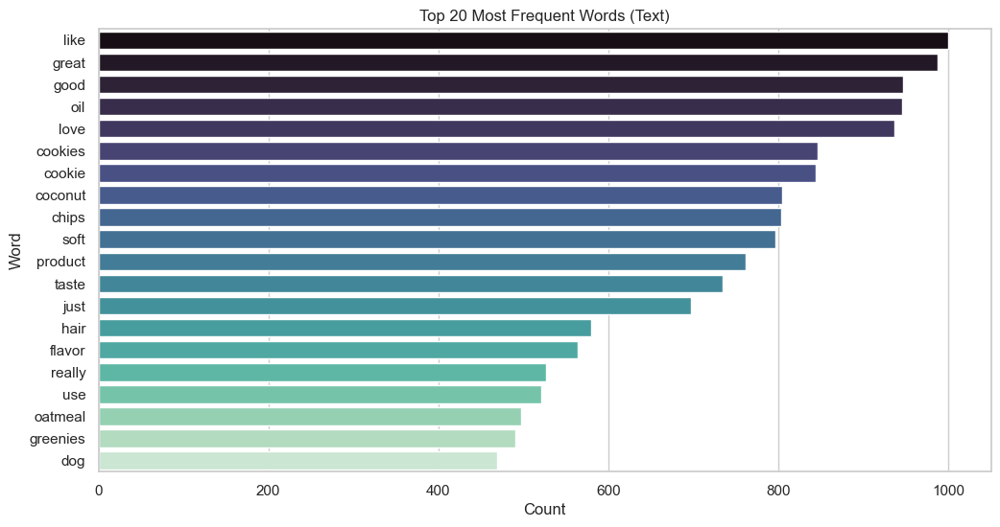

,word,count
0,like,1000
1,great,987
2,good,947
3,oil,945
4,love,936
5,cookies,846
6,cookie,844
7,coconut,804
8,chips,803
9,soft,797


In [ ]:
def basic_tokenize(text: str) -> List[str]:
    if not isinstance(text, str):
        return []
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    tokens = text.lower().split()
    return [t for t in tokens if len(t) > 1]

all_tokens = []
for t in tqdm(df["Text"], desc="Tokenizing for top words"):
    all_tokens.extend(basic_tokenize(t))

stopwords_all = load_stopwords(STOPWORDS_PATH)
filtered_tokens = [tok for tok in all_tokens if tok not in stopwords_all]

top20 = Counter(filtered_tokens).most_common(20)
word_df = pd.DataFrame(top20, columns=["word", "count"])

plt.figure(figsize=(12, 6))
sns.barplot(data=word_df, x="count", y="word", palette="mako")
plt.title("Top 20 Most Frequent Words (Text)")
plt.xlabel("Count")
plt.ylabel("Word")
plt.show()

word_df


## 4) Modular Preprocessing Framework

In [22]:
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Try to ensure required NLTK resources are available
for pkg in ["wordnet", "omw-1.4", "averaged_perceptron_tagger"]:
    try:
        nltk.data.find(f"corpora/{pkg}") if pkg in {"wordnet", "omw-1.4"} else nltk.data.find(f"taggers/{pkg}")
    except LookupError:
        nltk.download(pkg, quiet=True)

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()


def normalize_english_text(text: str) -> str:
    """Basic text normalization: unicode normalization, trim, and lowercase."""
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = text.strip().lower()
    return text


def remove_links_mentions(text: str) -> str:
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    return text


def remove_html(text: str) -> str:
    return re.sub(r"<[^>]+>", " ", text)


def lowercase(text: str) -> str:
    return text.lower()


def remove_non_textual_chars(text: str) -> str:
    return re.sub(r"[^a-zA-Z0-9\s]", " ", text)


def normalize_whitespace(text: str) -> str:
    return re.sub(r"\s+", " ", text).strip()


def remove_stopwords(text: str, stopwords: set) -> str:
    tokens = text.split()
    tokens = [t for t in tokens if t not in stopwords]
    return " ".join(tokens)


def stem_simple_english(text: str) -> str:
    tokens = text.split()
    stemmed = [stemmer.stem(tok) for tok in tokens]
    return " ".join(stemmed)


def _to_wordnet_pos(treebank_tag: str) -> str:
    if treebank_tag.startswith("J"):
        return "a"  # adjective
    if treebank_tag.startswith("V"):
        return "v"  # verb
    if treebank_tag.startswith("N"):
        return "n"  # noun
    if treebank_tag.startswith("R"):
        return "r"  # adverb
    return "n"


def lemmatize_optional(text: str) -> str:
    tokens = text.split()
    if not tokens:
        return ""

    try:
        tagged = nltk.pos_tag(tokens)
        lemmas = [lemmatizer.lemmatize(tok, _to_wordnet_pos(pos)) for tok, pos in tagged]
    except LookupError:
        # Fallback if POS tagger resources are unavailable in this environment
        lemmas = [lemmatizer.lemmatize(tok) for tok in tokens]

    return " ".join(lemmas)


def compose_preprocessor(functions: List[Callable[[str], str]], stopwords: Optional[set] = None) -> Callable[[str], str]:
    def _apply(text: str) -> str:
        out = text if isinstance(text, str) else ""
        for fn in functions:
            if fn.__name__ == "remove_stopwords":
                out = fn(out, stopwords or set())
            else:
                out = fn(out)
        return out
    return _apply


# Define preprocessing scenarios for comparison
PREPROCESS_CONFIGS = {
    "minimal": [normalize_whitespace, lowercase],
    "basic_clean": [normalize_english_text, remove_html, remove_links_mentions, lowercase, remove_non_textual_chars, normalize_whitespace],
    "basic_plus_stopwords": [normalize_english_text, remove_html, remove_links_mentions, lowercase, remove_non_textual_chars, normalize_whitespace, remove_stopwords],
    "basic_stop_stem": [normalize_english_text, remove_html, remove_links_mentions, lowercase, remove_non_textual_chars, normalize_whitespace, remove_stopwords, stem_simple_english],
    "basic_stop_lemma": [normalize_english_text, remove_html, remove_links_mentions, lowercase, remove_non_textual_chars, normalize_whitespace, remove_stopwords, lemmatize_optional],
}

print("Available preprocessing configs:")
for name in PREPROCESS_CONFIGS:
    print("-", name)


Available preprocessing configs:
- minimal
- basic_clean
- basic_plus_stopwords
- basic_stop_stem
- basic_stop_lemma


## 5) Text Source Feature Flags (Text / Summary / Combined)

In [23]:

@dataclass
class TextFeatureConfig:
    mode: str  # one of: text, summary, concat, weighted
    summary_weight: float = 0.7
    text_weight: float = 0.3


def build_text_columns(data: pd.DataFrame, pre_fn: Callable[[str], str], cfg: TextFeatureConfig) -> pd.DataFrame:
    tmp = data.copy()
    tmp["Text_clean"] = tmp["Text"].fillna("").map(pre_fn)
    tmp["Summary_clean"] = tmp["Summary"].fillna("").map(pre_fn)

    if cfg.mode == "text":
        tmp["model_text"] = tmp["Text_clean"]
    elif cfg.mode == "summary":
        tmp["model_text"] = tmp["Summary_clean"]
    elif cfg.mode == "concat":
        tmp["model_text"] = (tmp["Summary_clean"] + " " + tmp["Text_clean"]).str.strip()
    elif cfg.mode == "weighted":
        # In weighted mode, model_text is kept only for traceability.
        tmp["model_text"] = (tmp["Summary_clean"] + " ||| " + tmp["Text_clean"]).str.strip()
    else:
        raise ValueError(f"Unknown mode: {cfg.mode}")

    return tmp


## 6) Embedding Extraction (SentenceTransformer)

In [24]:

from sentence_transformers import SentenceTransformer

# Important: in offline environments, the model must already exist in local cache or local folder.
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
LOCAL_MODEL_DIR = "./models/all-MiniLM-L6-v2"


def load_embedding_model() -> SentenceTransformer:
    # 1) Project local path (recommended for offline execution)
    if os.path.isdir(LOCAL_MODEL_DIR):
        print(f"Loading SentenceTransformer from local dir: {LOCAL_MODEL_DIR}")
        return SentenceTransformer(LOCAL_MODEL_DIR)

    # 2) Load only from local HuggingFace cache (no network)
    try:
        print("Trying offline cache (local_files_only=True)...")
        return SentenceTransformer(MODEL_NAME, local_files_only=True)
    except Exception as e_offline:
        print(f"Offline cache load failed: {e_offline}")

    # 3) Try online download (if network is available)
    try:
        print("Trying online download from HuggingFace...")
        return SentenceTransformer(MODEL_NAME)
    except Exception as e_online:
        raise RuntimeError(
            "Could not load all-MiniLM-L6-v2. "
            "Use internet once to download/cache the model, or place it under "
            f"{LOCAL_MODEL_DIR}. Original error: {e_online}"
        )


model = load_embedding_model()


def encode_texts(texts: List[str], batch_size: int = 128) -> np.ndarray:
    vectors = model.encode(
        texts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )
    return vectors


def get_embeddings(data: pd.DataFrame, cfg: TextFeatureConfig, batch_size: int = 128) -> np.ndarray:
    if cfg.mode in {"text", "summary", "concat"}:
        return encode_texts(data["model_text"].tolist(), batch_size=batch_size)

    # Weighted mode: encode summary and text separately, then linearly combine embeddings
    summary_emb = encode_texts(data["Summary_clean"].tolist(), batch_size=batch_size)
    text_emb = encode_texts(data["Text_clean"].tolist(), batch_size=batch_size)
    emb = cfg.summary_weight * summary_emb + cfg.text_weight * text_emb

    # Re-normalize after linear combination
    norms = np.linalg.norm(emb, axis=1, keepdims=True) + 1e-12
    emb = emb / norms
    return emb


Loading SentenceTransformer from local dir: ./models/all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

## 7) Clustering Utilities + Hyperparameter Tuning

In [25]:

from sklearn.metrics import (
    silhouette_score,
    homogeneity_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.preprocessing import normalize as sk_normalize
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform


def log_step(msg: str, verbose: bool = True):
    if verbose:
        print(f"[LOG] {msg}")


def time_block_start():
    return time.perf_counter()


def time_block_end(t0: float) -> float:
    return time.perf_counter() - t0


def count_effective_clusters(labels: np.ndarray) -> int:
    uniq = set(np.asarray(labels).tolist())
    return len(uniq - {-1})


def _cluster_size_stats(labels: np.ndarray) -> Tuple[int, int]:
    labels = np.asarray(labels)
    non_noise = labels[labels != -1]
    if len(non_noise) == 0:
        return 0, 0
    counts = pd.Series(non_noise).value_counts()
    return int(counts.min()), int(counts.max())


def evaluate_internal_metrics(X: np.ndarray, labels: np.ndarray) -> Dict[str, float]:
    """
    Internal metrics are computed on non-noise points only (label != -1).
    """
    labels = np.asarray(labels)
    valid_mask = labels != -1
    n_non_noise = int(valid_mask.sum())
    n_clusters = count_effective_clusters(labels)
    noise_count = int(np.sum(labels == -1))

    min_cluster_size, max_cluster_size = _cluster_size_stats(labels)

    metrics = {
        "n_clusters": int(n_clusters),
        "n_non_noise": int(n_non_noise),
        "noise_count": int(noise_count),
        "noise_ratio": float(noise_count / max(1, len(labels))),
        "min_cluster_size": int(min_cluster_size),
        "max_cluster_size": int(max_cluster_size),
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
    }

    # Rule: compute only if non-noise samples >=2 and at least 2 clusters
    if n_non_noise < 2 or n_clusters < 2:
        return metrics

    X_eval = X[valid_mask]
    y_eval = labels[valid_mask]

    try:
        metrics["silhouette"] = float(silhouette_score(X_eval, y_eval))
    except Exception:
        pass
    try:
        metrics["davies_bouldin"] = float(davies_bouldin_score(X_eval, y_eval))
    except Exception:
        pass
    try:
        metrics["calinski_harabasz"] = float(calinski_harabasz_score(X_eval, y_eval))
    except Exception:
        pass

    return metrics


def add_homogeneity(metric_dict: Dict[str, float], labels: np.ndarray, score_labels: Optional[np.ndarray]):
    metric_dict = dict(metric_dict)
    metric_dict["homogeneity_wrt_score"] = np.nan
    # NOTE: Review "Score" is NOT a ground-truth cluster label.
    # This metric is used only as a proxy to measure correlation between discovered clusters and review scores.
    if score_labels is not None:
        try:
            metric_dict["homogeneity_wrt_score"] = float(homogeneity_score(score_labels, labels))
        except Exception:
            pass
    return metric_dict


def elbow_curve(X: np.ndarray, k_values=range(2, 16), random_state: int = 42, verbose: bool = True) -> pd.DataFrame:
    rows = []
    for k in tqdm(list(k_values), desc="KMeans elbow sweep", disable=not verbose):
        km = KMeans(n_clusters=k, random_state=random_state, n_init=20)
        km.fit(X)
        rows.append({"k": int(k), "inertia": float(km.inertia_)})
    return pd.DataFrame(rows)


def select_elbow_k(inertia_df: pd.DataFrame) -> int:
    x = inertia_df["k"].values.astype(float)
    y = inertia_df["inertia"].values.astype(float)

    p1 = np.array([x[0], y[0]])
    p2 = np.array([x[-1], y[-1]])
    line_vec = p2 - p1
    line_len = np.linalg.norm(line_vec) + 1e-12

    distances = []
    for xi, yi in zip(x, y):
        p = np.array([xi, yi])
        dist = np.abs(np.cross(line_vec, p - p1)) / line_len
        distances.append(dist)

    best_idx = int(np.argmax(distances))
    return int(x[best_idx])


def tune_kmeans_with_elbow(X: np.ndarray, k_values=range(2, 15), random_state: int = 42, verbose: bool = True):
    inertia_df = elbow_curve(X, k_values=k_values, random_state=random_state, verbose=verbose)
    best_k = select_elbow_k(inertia_df)

    model = KMeans(n_clusters=best_k, random_state=random_state, n_init=20)
    labels = model.fit_predict(X)
    metrics = evaluate_internal_metrics(X, labels)
    return inertia_df, best_k, model, labels, metrics


def _infer_dbscan_mode(X: np.ndarray) -> Dict[str, object]:
    n_samples, n_features = X.shape
    # data-driven threshold (avoids rigid magic number)
    high_dim_threshold = max(12, int(np.log2(max(2, n_samples)) * 2.5))
    is_high_dim = n_features >= high_dim_threshold

    if is_high_dim:
        return {
            "X_use": sk_normalize(X, norm="l2"),
            "metric": "cosine",
            "is_high_dim": True,
            "high_dim_threshold": high_dim_threshold,
        }

    return {
        "X_use": X,
        "metric": "euclidean",
        "is_high_dim": False,
        "high_dim_threshold": high_dim_threshold,
    }


def _kdist_eps_candidates(X_use: np.ndarray, min_samples: int, metric: str) -> List[float]:
    k = max(2, int(min_samples))
    nn = NearestNeighbors(n_neighbors=k, metric=metric)
    nn.fit(X_use)
    dists = nn.kneighbors(X_use)[0][:, -1]

    # quantile-based, scale-aware candidates
    qs = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95, 0.98]
    return [float(np.quantile(dists, q)) for q in qs]


def _dbscan_rank_score(silhouette: float, noise_ratio: float) -> float:
    sil = silhouette if np.isfinite(silhouette) else -1.0
    return float(sil - 0.5 * noise_ratio)


def _is_valid_dbscan_config(row: Dict[str, object], max_noise_ratio: float, min_cluster_size: int) -> bool:
    return (
        int(row["n_clusters"]) >= 2
        and float(row["noise_ratio"]) <= float(max_noise_ratio)
        and int(row["min_cluster_size"]) >= int(min_cluster_size)
    )


def tune_dbscan(
    X: np.ndarray,
    eps_values=np.linspace(0.1, 2.0, 20),
    min_samples_values=range(3, 15),
    verbose: bool = True,
    max_noise_ratio: float = 0.60,
    min_cluster_size: int = 10,
) -> pd.DataFrame:
    mode = _infer_dbscan_mode(X)
    X_use = mode["X_use"]
    metric = mode["metric"]

    rows = []

    for min_samples in tqdm(list(min_samples_values), desc="DBSCAN min_samples", disable=not verbose):
        # fixed grid + k-distance adaptive candidates
        eps_candidates = set(float(e) for e in eps_values)
        try:
            eps_candidates.update(_kdist_eps_candidates(X_use, min_samples=min_samples, metric=metric))
        except Exception:
            pass

        eps_candidates = sorted(e for e in eps_candidates if np.isfinite(e) and e > 0)

        for eps in eps_candidates:
            model = DBSCAN(eps=float(eps), min_samples=int(min_samples), metric=metric)
            labels = model.fit_predict(X_use)

            m = evaluate_internal_metrics(X_use, labels)
            row = {
                "eps": float(eps),
                "min_samples": int(min_samples),
                "metric": metric,
                "is_high_dim": bool(mode["is_high_dim"]),
                **m,
            }
            row["valid_for_selection"] = _is_valid_dbscan_config(
                row,
                max_noise_ratio=max_noise_ratio,
                min_cluster_size=min_cluster_size,
            )
            row["score"] = _dbscan_rank_score(row["silhouette"], row["noise_ratio"])
            rows.append(row)

    df = pd.DataFrame(rows)
    if df.empty:
        return df

    # selection-ready sorted dataframe
    valid_df = df[df["valid_for_selection"]].copy()
    target = valid_df if len(valid_df) > 0 else df

    target = target.sort_values(
        by=["score", "silhouette", "noise_ratio"],
        ascending=[False, False, True],
    ).reset_index(drop=True)

    return target


def fit_dbscan_with_params(X: np.ndarray, eps: float, min_samples: int):
    mode = _infer_dbscan_mode(X)
    model = DBSCAN(eps=float(eps), min_samples=int(min_samples), metric=mode["metric"])
    labels = model.fit_predict(mode["X_use"])
    return model, labels


def fit_dbscan_reduced_adaptive(
    X: np.ndarray,
    base_eps: float,
    min_samples: int,
    verbose: bool = False,
):
    """
    Adaptive DBSCAN tuning for reduced space with same validity/ranking logic.
    Signature unchanged.
    Returns best config + labels.
    """
    mode = _infer_dbscan_mode(X)
    X_use = mode["X_use"]
    metric = mode["metric"]

    ms_candidates = sorted({max(2, int(min_samples)), max(2, int(min_samples)-2), max(2, int(min_samples)-4), 3})

    all_rows = []
    for ms in ms_candidates:
        eps_candidates = {
            float(base_eps) * m
            for m in [0.20, 0.35, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 4.0]
        }
        try:
            eps_candidates.update(_kdist_eps_candidates(X_use, min_samples=ms, metric=metric))
        except Exception:
            pass

        eps_candidates = sorted(e for e in eps_candidates if np.isfinite(e) and e > 0)

        for eps in eps_candidates:
            model = DBSCAN(eps=float(eps), min_samples=int(ms), metric=metric)
            labels = model.fit_predict(X_use)
            m = evaluate_internal_metrics(X_use, labels)

            row = {
                "eps": float(eps),
                "min_samples": int(ms),
                "metric": metric,
                "is_high_dim": bool(mode["is_high_dim"]),
                "labels": labels,
                **m,
            }
            row["valid_for_selection"] = _is_valid_dbscan_config(
                row,
                max_noise_ratio=0.60,
                min_cluster_size=10,
            )
            row["score"] = _dbscan_rank_score(row["silhouette"], row["noise_ratio"])
            all_rows.append(row)

    tuning_df = pd.DataFrame([{k: v for k, v in r.items() if k != "labels"} for r in all_rows])

    if len(all_rows) == 0:
        model = DBSCAN(eps=float(base_eps), min_samples=int(min_samples), metric=metric)
        labels = model.fit_predict(X_use)
        m = evaluate_internal_metrics(X_use, labels)
        fallback = {
            "eps": float(base_eps),
            "min_samples": int(min_samples),
            "metric": metric,
            "labels": labels,
            "valid_for_selection": False,
            "score": _dbscan_rank_score(m["silhouette"], m["noise_ratio"]),
            **m,
        }
        return fallback["eps"], fallback["min_samples"], fallback["labels"], fallback, tuning_df

    valid_rows = [r for r in all_rows if r["valid_for_selection"]]
    selected_pool = valid_rows if len(valid_rows) > 0 else all_rows

    selected_pool = sorted(
        selected_pool,
        key=lambda r: (
            -r["score"],
            -(r["silhouette"] if np.isfinite(r["silhouette"]) else -1e9),
            r["noise_ratio"],
        ),
    )
    best = selected_pool[0]

    if verbose:
        log_step(
            f"DBSCAN adaptive best | metric={best['metric']} eps={best['eps']:.4f} "
            f"min_samples={best['min_samples']} clusters={best['n_clusters']} noise_ratio={best['noise_ratio']:.3f}",
            True,
        )

    tuning_df = tuning_df.sort_values(
        by=["score", "silhouette", "noise_ratio"],
        ascending=[False, False, True],
    ).reset_index(drop=True)

    return best["eps"], best["min_samples"], best["labels"], best, tuning_df


def _infer_agglomerative_mode(X: np.ndarray) -> Dict[str, object]:
    n_samples, n_features = X.shape
    high_dim_threshold = max(12, int(np.log2(max(2, n_samples)) * 2.5))
    is_high_dim = n_features >= high_dim_threshold

    if is_high_dim:
        return {
            "X_use": sk_normalize(X, norm="l2"),
            "is_high_dim": True,
            "high_dim_threshold": high_dim_threshold,
        }

    return {
        "X_use": X,
        "is_high_dim": False,
        "high_dim_threshold": high_dim_threshold,
    }


def _cluster_size_valid(labels: np.ndarray, min_size: int = 5) -> bool:
    labels = np.asarray(labels)
    counts = pd.Series(labels).value_counts()
    return len(counts) >= 2 and int(counts.min()) >= int(min_size)


def _is_single_linkage_degenerate(labels: np.ndarray, ratio_threshold: float = 0.80) -> bool:
    labels = np.asarray(labels)
    counts = pd.Series(labels).value_counts()
    if len(counts) == 0:
        return True
    return float(counts.max() / max(1, len(labels))) > float(ratio_threshold)


def _agg_metric_for_linkage(linkage_name: str, is_high_dim: bool) -> Optional[str]:
    if linkage_name == "ward":
        return None  # ward only supports euclidean internally
    return "cosine" if is_high_dim else "euclidean"


def _fit_agglomerative_core(X_use: np.ndarray, linkage_name: str, k: int, metric_name: Optional[str]):
    if linkage_name == "ward":
        model = AgglomerativeClustering(n_clusters=int(k), linkage="ward")
    else:
        model = AgglomerativeClustering(
            n_clusters=int(k),
            linkage=linkage_name,
            metric=metric_name,
        )
    labels = model.fit_predict(X_use)
    return model, labels


def tune_agglomerative(
    X: np.ndarray,
    linkages=("ward", "complete", "average", "single"),
    k_values=range(2, 15),
    verbose: bool = True,
) -> pd.DataFrame:
    mode = _infer_agglomerative_mode(X)
    X_use = mode["X_use"]
    is_high_dim = bool(mode["is_high_dim"])

    rows = []

    for lk in linkages:
        metric_name = _agg_metric_for_linkage(lk, is_high_dim=is_high_dim)

        for k in tqdm(list(k_values), desc=f"Agglomerative ({lk})", disable=not verbose):
            try:
                model, labels = _fit_agglomerative_core(
                    X_use,
                    linkage_name=lk,
                    k=int(k),
                    metric_name=metric_name,
                )
            except Exception:
                continue

            n_clusters = len(np.unique(labels))
            if n_clusters < 2:
                continue

            # Each cluster must contain at least 5 samples
            if not _cluster_size_valid(labels, min_size=5):
                continue

            # single linkage often forms one giant chain/cluster
            degenerate = False
            if lk == "single":
                degenerate = _is_single_linkage_degenerate(labels, ratio_threshold=0.80)
                if degenerate:
                    continue

            m = evaluate_internal_metrics(X_use, labels)

            sil = m.get("silhouette", np.nan)
            dbi = m.get("davies_bouldin", np.nan)
            ch = m.get("calinski_harabasz", np.nan)

            # Internal metrics must be finite
            if not (np.isfinite(sil) and np.isfinite(dbi) and np.isfinite(ch)):
                continue

            score = float(sil - 0.01 * dbi)

            rows.append({
                "linkage": lk,
                "k": int(k),
                "metric": "ward-euclidean" if lk == "ward" else metric_name,
                "is_high_dim": is_high_dim,
                "degenerate_single": bool(degenerate),
                "score": score,
                **m,
            })

    df = pd.DataFrame(rows)
    if df.empty:
        return df

    # robust ranking
    df = df.sort_values(
        by=["score", "silhouette", "davies_bouldin"],
        ascending=[False, False, True],
    ).reset_index(drop=True)

    return df


def fit_agglomerative_with_params(X: np.ndarray, linkage_name: str, k: int):
    mode = _infer_agglomerative_mode(X)
    X_use = mode["X_use"]
    metric_name = _agg_metric_for_linkage(linkage_name, is_high_dim=bool(mode["is_high_dim"]))

    model, labels = _fit_agglomerative_core(
        X_use,
        linkage_name=linkage_name,
        k=int(k),
        metric_name=metric_name,
    )
    return model, labels


def plot_elbow(inertia_df: pd.DataFrame, selected_k: int):
    plt.figure(figsize=(8, 5))
    sns.lineplot(data=inertia_df, x="k", y="inertia", marker="o", color="tab:blue")
    plt.axvline(selected_k, color="tab:red", linestyle="--", label=f"selected k={selected_k}")
    plt.title("KMeans Elbow Curve with Selected k")
    plt.xlabel("k")
    plt.ylabel("Inertia")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_dbscan_heatmap(dbscan_df: pd.DataFrame, value_col: str = "silhouette"):
    if dbscan_df.empty:
        print("DBSCAN tuning dataframe is empty.")
        return
    pv = dbscan_df.pivot_table(index="eps", columns="min_samples", values=value_col, aggfunc="mean")
    plt.figure(figsize=(10, 6))
    sns.heatmap(pv, cmap="viridis", annot=False)
    plt.title(f"DBSCAN {value_col} Heatmap")
    plt.xlabel("min_samples")
    plt.ylabel("eps")
    plt.tight_layout()
    plt.show()


def plot_agglomerative_heatmaps(agg_df: pd.DataFrame, value_col: str = "silhouette"):
    if agg_df.empty:
        print("Agglomerative tuning dataframe is empty.")
        return

    pv = agg_df.pivot_table(index="k", columns="linkage", values=value_col, aggfunc="mean")
    plt.figure(figsize=(8, 7))
    sns.heatmap(pv, cmap="magma", annot=False)
    plt.title(f"Agglomerative {value_col} Heatmap (k x linkage)")
    plt.xlabel("linkage")
    plt.ylabel("k")
    plt.tight_layout()
    plt.show()


## 8) Dimensionality Reduction and Visualization (UMAP)

In [26]:

def reduce_with_pca(X: np.ndarray, n_components: int = 2, random_state: int = 42):
    pca = PCA(n_components=n_components, random_state=random_state)
    Xr = pca.fit_transform(X)
    return pca, Xr


def reduce_with_tsne(X: np.ndarray, n_components: int = 2, random_state: int = 42):
    reducer = TSNE(n_components=n_components, random_state=random_state, init="pca", learning_rate="auto")
    Xr = reducer.fit_transform(X)
    return reducer, Xr


def _label_color_map(labels: np.ndarray):
    labels = np.asarray(labels)
    uniq = sorted(np.unique(labels).tolist())

    # Render DBSCAN noise points in gray
    noise_label = -1 if -1 in uniq else None
    non_noise = [u for u in uniq if u != -1]

    if len(non_noise) == 0:
        return {noise_label: "#9e9e9e"}

    palette = sns.color_palette("tab20", n_colors=max(3, len(non_noise)))
    cmap = {}
    for i, lab in enumerate(non_noise):
        cmap[lab] = palette[i % len(palette)]

    if noise_label is not None:
        cmap[noise_label] = "#9e9e9e"

    return cmap


def _scatter_on_ax(ax, X2d: np.ndarray, labels: np.ndarray, title: str):
    labels = np.asarray(labels)
    d = pd.DataFrame({"x": X2d[:, 0], "y": X2d[:, 1], "cluster": labels})

    cmap = _label_color_map(labels)

    sns.scatterplot(
        data=d,
        x="x",
        y="y",
        hue="cluster",
        palette=cmap,
        s=14,
        linewidth=0,
        ax=ax,
        legend=False,
    )

    n_effective = len(set(labels.tolist()) - {-1})
    noise_count = int(np.sum(labels == -1)) if -1 in set(labels.tolist()) else 0

    suffix = f" | clusters={n_effective}"
    if noise_count > 0:
        suffix += f", noise={noise_count}"

    if n_effective < 2:
        suffix += " [weak separation]"

    ax.set_title(title + suffix)
    ax.set_xlabel("")
    ax.set_ylabel("")


def plot_1x3_cluster_grid(X2d: np.ndarray, labels_dict: Dict[str, np.ndarray], suptitle: str):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    algos = ["kmeans", "dbscan", "hierarchical"]

    for ax, algo in zip(axes, algos):
        labs = np.asarray(labels_dict[algo])
        uniq = sorted(np.unique(labs).tolist())
        print(f"[PLOT] {algo}: unique labels={uniq[:12]}{'...' if len(uniq)>12 else ''}")
        _scatter_on_ax(ax, X2d, labs, title=algo.capitalize())

    fig.suptitle(suptitle, y=1.02, fontsize=12)
    plt.tight_layout()
    plt.show()


## 9) Unified Experiment Environment (Tuned Params + Before/After DR Comparison)

In [27]:

@dataclass
class ExperimentConfig:
    preprocess_name: str
    text_feature_cfg: TextFeatureConfig
    sample_size: Optional[int] = 8000


def sample_df(data: pd.DataFrame, sample_size: Optional[int], random_state: int = 42) -> pd.DataFrame:
    if sample_size is None or sample_size >= len(data):
        out = data.copy()
    else:
        out = data.sample(sample_size, random_state=random_state)

    out = out.copy()
    out["_source_index"] = out.index.astype(int)
    return out.reset_index(drop=True)


def _fit_all_algorithms_with_tuning(X: np.ndarray, score_labels: np.ndarray, verbose: bool = True, prefix: str = ""):
    # KMeans
    t0 = time_block_start()
    log_step(f"{prefix}KMeans tuning started...", verbose)
    kmeans_elbow_df, km_best_k, km_model, km_labels, km_m = tune_kmeans_with_elbow(
        X, k_values=range(2, 15), random_state=RANDOM_STATE, verbose=verbose
    )
    km_m = add_homogeneity(km_m, km_labels, score_labels)
    log_step(f"{prefix}KMeans tuning done in {time_block_end(t0):.2f}s | best_k={km_best_k}", verbose)

    # DBSCAN
    t0 = time_block_start()
    log_step(f"{prefix}DBSCAN tuning started...", verbose)
    dbscan_tuning_df = tune_dbscan(
        X,
        eps_values=np.linspace(0.1, 4.0, 20),
        min_samples_values=range(3, 20),
        verbose=verbose,
        max_noise_ratio=0.60,
        min_cluster_size=10,
    )
    if dbscan_tuning_df.empty:
        raise RuntimeError(f"{prefix}DBSCAN tuning produced no candidate.")

    has_valid = ("valid_for_selection" in dbscan_tuning_df.columns) and bool(dbscan_tuning_df["valid_for_selection"].any())
    if not has_valid:
        raise RuntimeError(
            f"{prefix}DBSCAN: no valid configuration passed constraints "
            f"(n_clusters>=2, noise_ratio<=0.60, min_cluster_size>=10)."
        )

    db_best_row = dbscan_tuning_df[dbscan_tuning_df["valid_for_selection"]].iloc[0]
    db_model, db_labels = fit_dbscan_with_params(
        X,
        eps=float(db_best_row["eps"]),
        min_samples=int(db_best_row["min_samples"]),
    )
    db_m = add_homogeneity(evaluate_internal_metrics(_infer_dbscan_mode(X)["X_use"], db_labels), db_labels, score_labels)
    log_step(
        f"{prefix}DBSCAN best eps={db_best_row['eps']:.4f} min_samples={int(db_best_row['min_samples'])} "
        f"sil={db_best_row['silhouette']:.4f} noise={db_best_row['noise_ratio']:.3f}",
        verbose,
    )
    log_step(f"{prefix}DBSCAN tuning done in {time_block_end(t0):.2f}s | tested={len(dbscan_tuning_df)}", verbose)

    # Agglomerative
    t0 = time_block_start()
    log_step(f"{prefix}Agglomerative tuning started...", verbose)
    agg_tuning_df = tune_agglomerative(
        X,
        linkages=["ward", "complete", "average", "single"],
        k_values=range(2, 15),
        verbose=verbose,
    )
    if agg_tuning_df.empty:
        raise RuntimeError(f"{prefix}Agglomerative: no valid configuration passed constraints.")

    agg_best_row = agg_tuning_df.iloc[0]
    agg_model, agg_labels = fit_agglomerative_with_params(
        X,
        linkage_name=str(agg_best_row["linkage"]),
        k=int(agg_best_row["k"]),
    )
    agg_m = add_homogeneity(evaluate_internal_metrics(X, agg_labels), agg_labels, score_labels)
    log_step(f"{prefix}Agglomerative tuning done in {time_block_end(t0):.2f}s | tested={len(agg_tuning_df)}", verbose)

    labels = {
        "kmeans": km_labels,
        "dbscan": db_labels,
        "hierarchical": agg_labels,
    }
    metrics = {
        "kmeans": km_m,
        "dbscan": db_m,
        "hierarchical": agg_m,
    }
    params = {
        "kmeans": {"k": int(km_best_k)},
        "dbscan": {
            "eps": float(db_best_row["eps"]),
            "min_samples": int(db_best_row["min_samples"]),
            "metric": str(db_best_row["metric"]),
        },
        "hierarchical": {"linkage": str(agg_best_row["linkage"]), "k": int(agg_best_row["k"])},
    }

    return {
        "labels": labels,
        "metrics": metrics,
        "params": params,
        "kmeans_elbow_df": kmeans_elbow_df,
        "dbscan_tuning_df": dbscan_tuning_df,
        "agg_tuning_df": agg_tuning_df,
    }


def run_experiment(data: pd.DataFrame, cfg: ExperimentConfig, plot: bool = True, verbose: bool = True) -> Dict[str, object]:
    t_all = time_block_start()
    log_step(
        f"Starting experiment | preprocess={cfg.preprocess_name}, mode={cfg.text_feature_cfg.mode}, sample_size={cfg.sample_size}",
        verbose,
    )

    work = sample_df(data, cfg.sample_size, RANDOM_STATE)
    log_step(f"Sampled rows: {len(work)}", verbose)

    t0 = time_block_start()
    pre_functions = PREPROCESS_CONFIGS[cfg.preprocess_name]
    pre_fn = compose_preprocessor(pre_functions, stopwords=stopwords_all)
    work = build_text_columns(work, pre_fn, cfg.text_feature_cfg)
    log_step(f"Preprocessing done in {time_block_end(t0):.2f}s", verbose)

    t0 = time_block_start()
    log_step("Embedding extraction started...", verbose)
    cache_key = (
        tuple(work["_source_index"].tolist()),
        cfg.preprocess_name,
        cfg.text_feature_cfg.mode,
    )
    if cache_key in EMBEDDING_CACHE:
        embeddings = EMBEDDING_CACHE[cache_key]
        log_step("Embedding cache hit.", verbose)
    else:
        embeddings = get_embeddings(work, cfg.text_feature_cfg, batch_size=128)
        EMBEDDING_CACHE[cache_key] = embeddings
        log_step("Embedding cache miss; computed and stored.", verbose)
    log_step(f"Embedding extraction done in {time_block_end(t0):.2f}s | shape={embeddings.shape}", verbose)

    score_labels = work["Score"].fillna(-1).astype(int).values

    # --------- full tuning on original embedding space ---------
    original = _fit_all_algorithms_with_tuning(embeddings, score_labels, verbose=verbose, prefix="[Original] ")

    # --------- dimensionality reduction ---------
    t0 = time_block_start()
    log_step("PCA reduction started...", verbose)
    pca_model, X_pca2 = reduce_with_pca(embeddings, n_components=2, random_state=RANDOM_STATE)
    log_step(f"PCA reduction done in {time_block_end(t0):.2f}s", verbose)

    t0 = time_block_start()
    log_step("TSNE reduction started (this can be slow)...", verbose)
    tsne_model, X_tsne2 = reduce_with_tsne(embeddings, n_components=2, random_state=RANDOM_STATE)
    log_step(f"TSNE reduction done in {time_block_end(t0):.2f}s", verbose)

    if plot:
        plot_1x3_cluster_grid(
            X_pca2,
            original["labels"],
            suptitle="Original-space tuned labels projected on PCA (1x3)",
        )
        plot_1x3_cluster_grid(
            X_tsne2,
            original["labels"],
            suptitle="Original-space tuned labels projected on TSNE (1x3)",
        )

    # --------- full tuning again on reduced spaces ---------
    # TSNE is primarily designed for visualization.
    # Clustering in TSNE space can distort the true distance structure of the original data.
    # Therefore, TSNE-space clustering results should be treated as exploratory, not definitive.
    t0 = time_block_start()
    log_step("Full re-tuning on PCA space started...", verbose)
    pca_tuned = _fit_all_algorithms_with_tuning(X_pca2, score_labels, verbose=verbose, prefix="[PCA] ")
    log_step("Full re-tuning on TSNE space started...", verbose)
    tsne_tuned = _fit_all_algorithms_with_tuning(X_tsne2, score_labels, verbose=verbose, prefix="[TSNE] ")
    log_step(f"Full re-tuning on reduced spaces done in {time_block_end(t0):.2f}s", verbose)

    reduced_outputs = {
        "PCA": {
            "X2d": X_pca2,
            "labels": pca_tuned["labels"],
            "metrics": pca_tuned["metrics"],
            "params": pca_tuned["params"],
            "kmeans_elbow_df": pca_tuned["kmeans_elbow_df"],
            "dbscan_tuning_df": pca_tuned["dbscan_tuning_df"],
            "agg_tuning_df": pca_tuned["agg_tuning_df"],
        },
        "TSNE": {
            "X2d": X_tsne2,
            "labels": tsne_tuned["labels"],
            "metrics": tsne_tuned["metrics"],
            "params": tsne_tuned["params"],
            "kmeans_elbow_df": tsne_tuned["kmeans_elbow_df"],
            "dbscan_tuning_df": tsne_tuned["dbscan_tuning_df"],
            "agg_tuning_df": tsne_tuned["agg_tuning_df"],
        },
    }

    if plot:
        plot_1x3_cluster_grid(
            reduced_outputs["PCA"]["X2d"],
            reduced_outputs["PCA"]["labels"],
            suptitle="Re-clustered on PCA space (1x3)",
        )
        plot_1x3_cluster_grid(
            reduced_outputs["TSNE"]["X2d"],
            reduced_outputs["TSNE"]["labels"],
            suptitle="Re-clustered on TSNE space (1x3)",
        )

    log_step(f"Experiment finished in {time_block_end(t_all):.2f}s", verbose)

    return {
        "config": cfg,
        "work_df": work,
        "embeddings": embeddings,
        "labels_original": original["labels"],
        "metrics_original": original["metrics"],
        "best_params": {"Original": original["params"], "PCA": pca_tuned["params"], "TSNE": tsne_tuned["params"]},
        "kmeans_elbow_df": original["kmeans_elbow_df"],
        "dbscan_tuning_df": original["dbscan_tuning_df"],
        "agg_tuning_df": original["agg_tuning_df"],
        "reduced_outputs": reduced_outputs,
        "alt_method": "TSNE",
    }


## 10) Run One Baseline Experiment + Show Best Params

[LOG] Starting experiment | preprocess=basic_plus_stopwords, mode=concat, sample_size=6000
[LOG] Sampled rows: 2732
[LOG] Preprocessing done in 0.10s
[LOG] Embedding extraction started...


Batches:   0%|          | 0/22 [00:00<?, ?it/s]

[LOG] Embedding cache miss; computed and stored.
[LOG] Embedding extraction done in 6.85s | shape=(2732, 384)
[LOG] [Original] KMeans tuning started...


KMeans elbow sweep:   0%|          | 0/13 [00:00<?, ?it/s]

[LOG] [Original] KMeans tuning done in 8.94s | best_k=4
[LOG] [Original] DBSCAN tuning started...


...

Agglomerative (ward):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (complete):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (average):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (single):   0%|          | 0/13 [00:00<?, ?it/s]

[LOG] [Original] Agglomerative tuning done in 68.40s | tested=19
[LOG] PCA reduction started...
[LOG] PCA reduction done in 0.04s
[LOG] TSNE reduction started (this can be slow)...
[LOG] TSNE reduction done in 7.56s
[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


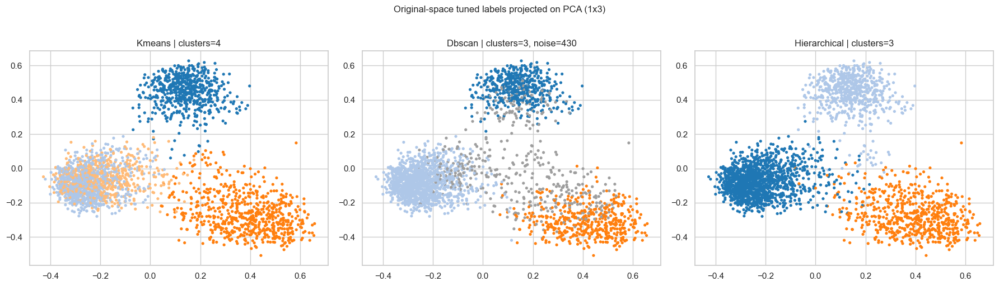

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


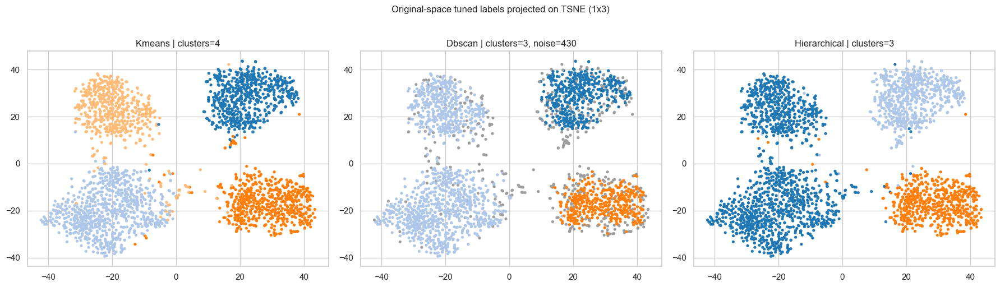

[LOG] Full re-tuning on PCA space started...
[LOG] [PCA] KMeans tuning started...


KMeans elbow sweep:   0%|          | 0/13 [00:00<?, ?it/s]

[LOG] [PCA] KMeans tuning done in 1.71s | best_k=3
[LOG] [PCA] DBSCAN tuning started...


DBSCAN min_samples:   0%|          | 0/17 [00:00<?, ?it/s]

[LOG] [PCA] DBSCAN best eps=0.0476 min_samples=18 sil=0.7585 noise=0.064
[LOG] [PCA] DBSCAN tuning done in 20.24s | tested=78
[LOG] [PCA] Agglomerative tuning started...


...

Agglomerative (ward):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (complete):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (average):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (single):   0%|          | 0/13 [00:00<?, ?it/s]

[LOG] [TSNE] Agglomerative tuning done in 5.20s | tested=40
[LOG] Full re-tuning on reduced spaces done in 54.36s
[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


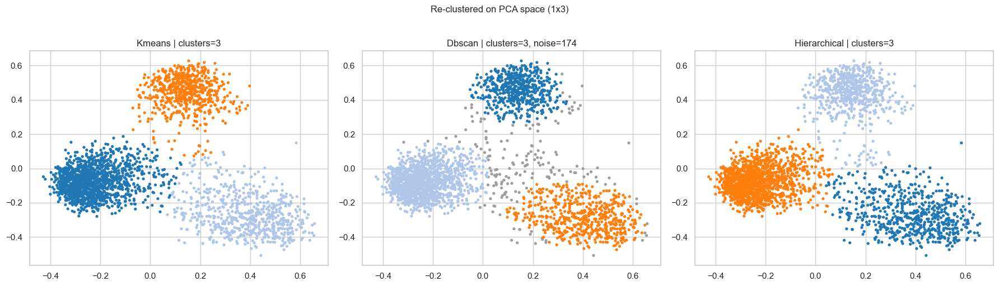

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


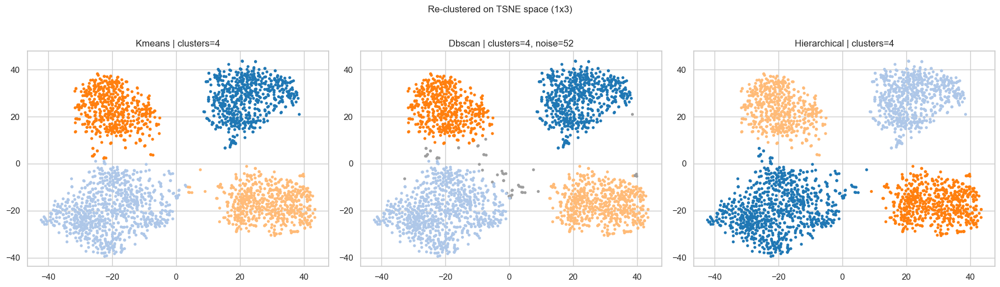

[LOG] Experiment finished in 186.64s
Done. Alternative DR method used: TSNE
Best parameters:
{'kmeans': {'k': 4}, 'dbscan': {'eps': 0.32398125529289246, 'min_samples': 18, 'metric': 'cosine'}, 'hierarchical': {'linkage': 'ward', 'k': 3}}


In [28]:

baseline_cfg = ExperimentConfig(
    preprocess_name="basic_plus_stopwords",
    text_feature_cfg=TextFeatureConfig(mode="concat"),
    sample_size=6000,
)

results = run_experiment(df, baseline_cfg, plot=True)
print("Done. Alternative DR method used:", results["alt_method"])
print("Best parameters:")
print(results["best_params"]["Original"])



### Live Logs / Quick Debug
If execution is slow:
- `verbose=True` prints step-by-step logs and per-stage timing.
- For quick debugging, reduce `sample_size` (e.g., 1200 or 2000).
- The slowest stages are usually `TSNE` and DBSCAN/Agglomerative grid search.


In [29]:

print("Original-space metrics (tuned models):")
pd.DataFrame(results["metrics_original"]).T


Original-space metrics (tuned models):


,n_clusters,n_non_noise,noise_count,noise_ratio,min_cluster_size,max_cluster_size,silhouette,davies_bouldin,calinski_harabasz,homogeneity_wrt_score
kmeans,4.0,2732.0,0.0,0.000000,599.0,872.0,0.140159,2.226529,317.823930,0.030532
dbscan,3.0,2302.0,430.0,0.157394,447.0,1348.0,0.172809,2.026568,338.778978,0.029567
hierarchical,3.0,2732.0,0.0,0.000000,613.0,1479.0,0.147703,2.263957,337.492241,0.018730


In [30]:

print("Metrics comparison: Original vs Reduced-space re-clustering")
rows = []
for algo, m in results["metrics_original"].items():
    rows.append({"space": "Original", "algorithm": algo, **m})

for red_name, payload in results["reduced_outputs"].items():
    for algo, m in payload["metrics"].items():
        rows.append({"space": red_name, "algorithm": algo, **m})

metrics_compare_df = pd.DataFrame(rows)
metrics_compare_df.sort_values(["algorithm", "space"]).reset_index(drop=True)


Metrics comparison: Original vs Reduced-space re-clustering


,space,algorithm,n_clusters,n_non_noise,noise_count,noise_ratio,min_cluster_size,max_cluster_size,silhouette,davies_bouldin,calinski_harabasz,homogeneity_wrt_score
0,Original,dbscan,3,2302,430,0.157394,447,1348,0.172809,2.026568,338.778978,0.029567
1,PCA,dbscan,3,2558,174,0.063690,556,1424,0.758530,0.339192,11992.988812,0.023055
2,TSNE,dbscan,4,2680,52,0.019034,544,891,0.662581,0.447337,7665.984310,0.031617
3,Original,hierarchical,3,2732,0,0.000000,613,1479,0.147703,2.263957,337.492241,0.018730
4,PCA,hierarchical,3,2732,0,0.000000,630,1456,0.711056,0.397886,9120.052455,0.018568
5,TSNE,hierarchical,4,2732,0,0.000000,552,929,0.648018,0.465349,7195.510206,0.029835
6,Original,kmeans,4,2732,0,0.000000,599,872,0.140159,2.226529,317.823930,0.030532
7,PCA,kmeans,3,2732,0,0.000000,629,1472,0.715032,0.396250,9359.443420,0.018145
8,TSNE,kmeans,4,2732,0,0.000000,563,912,0.649117,0.465806,7260.304258,0.030018


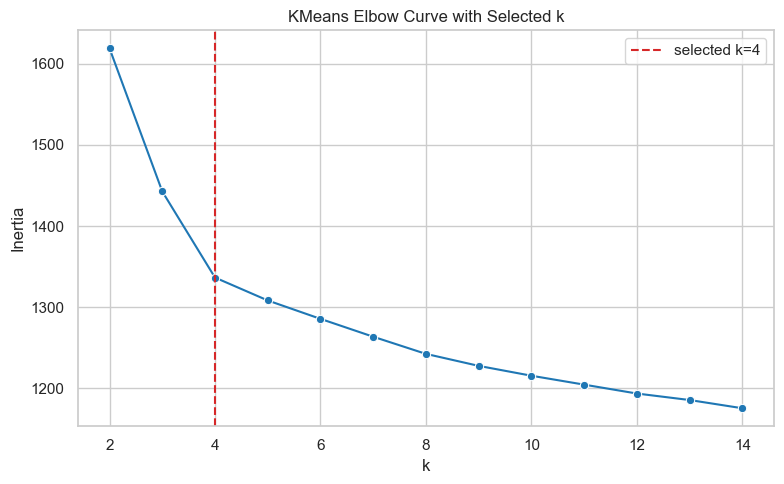

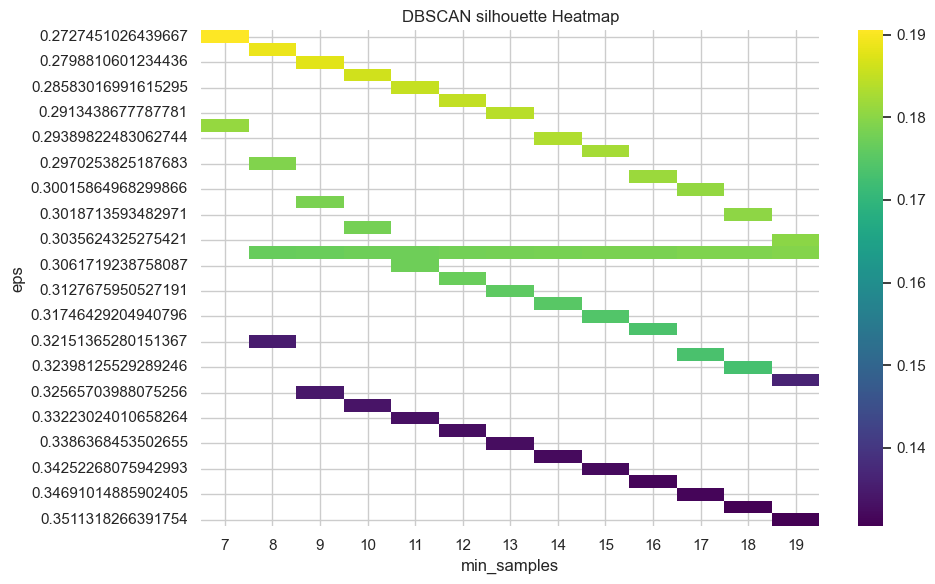

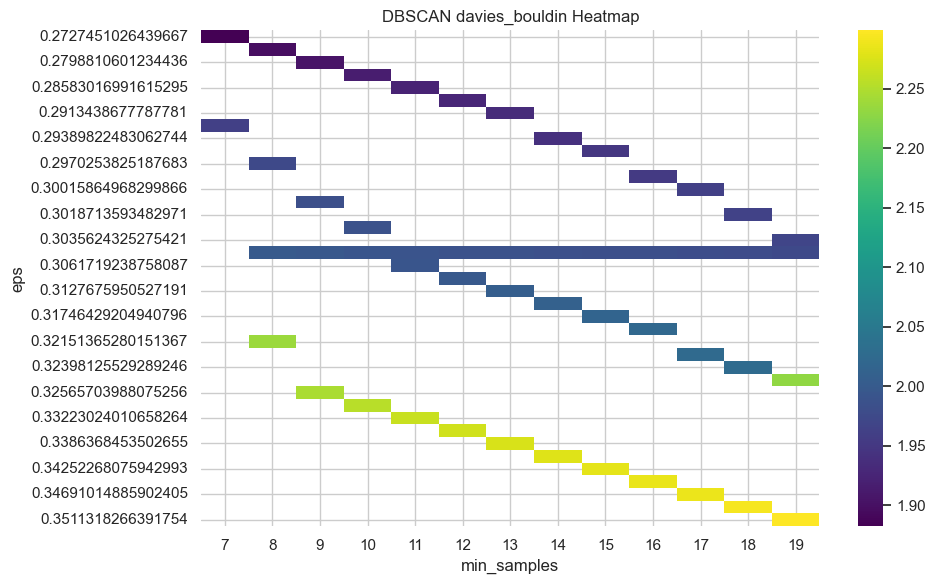

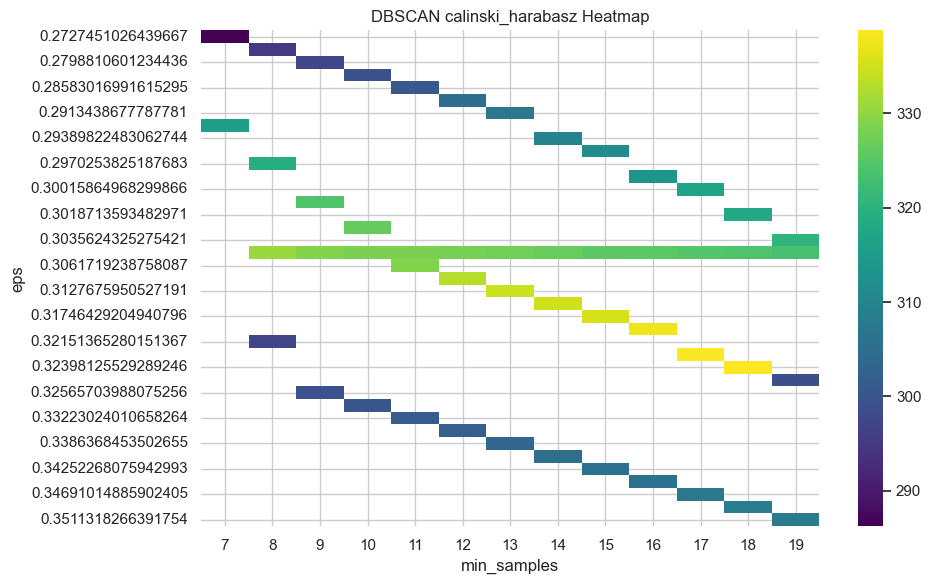

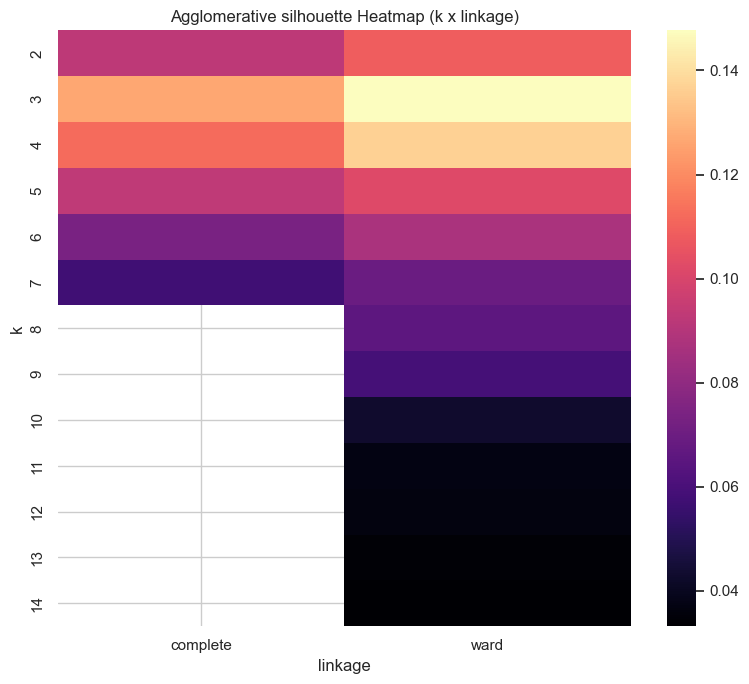

In [31]:

# Tuning visualizations
plot_elbow(results["kmeans_elbow_df"], selected_k=results["best_params"]["Original"]["kmeans"]["k"])
plot_dbscan_heatmap(results["dbscan_tuning_df"], value_col="silhouette")
plot_dbscan_heatmap(results["dbscan_tuning_df"], value_col="davies_bouldin")
plot_dbscan_heatmap(results["dbscan_tuning_df"], value_col="calinski_harabasz")
plot_agglomerative_heatmaps(results["agg_tuning_df"], value_col="silhouette")


## 11) Compare Multiple Preprocessing / Feature Configurations

Trial configs:   0%|          | 0/6 [00:00<?, ?it/s]

Batches:   0%|          | 0/22 [00:00<?, ?it/s]

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


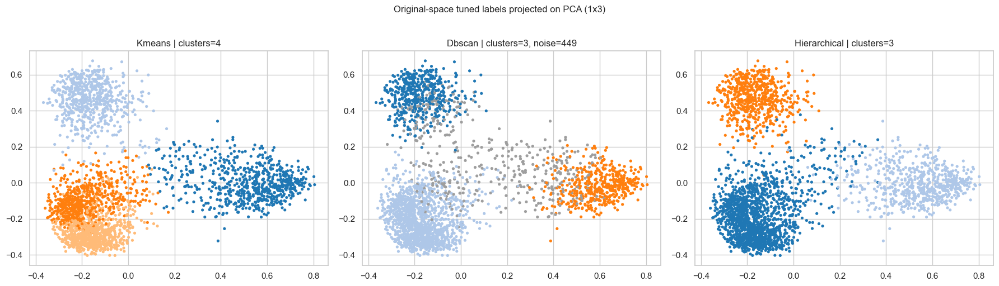

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


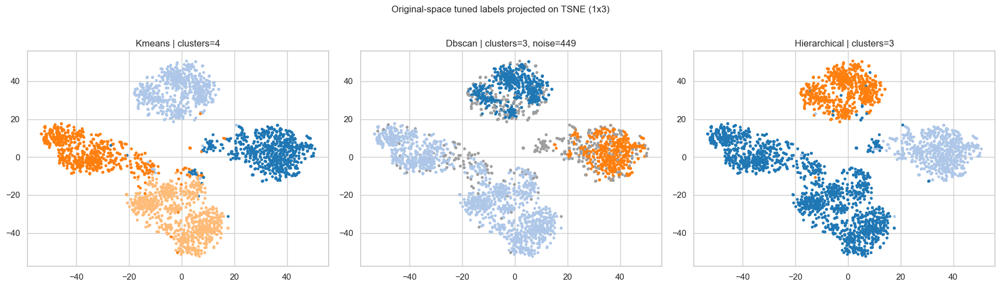

[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


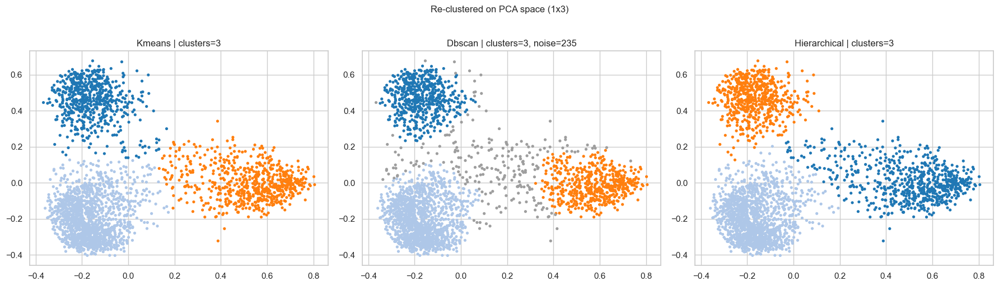

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


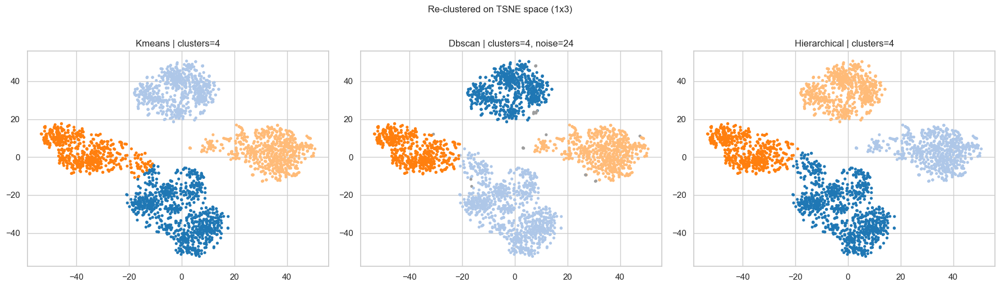

Batches:   0%|          | 0/22 [00:00<?, ?it/s]

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


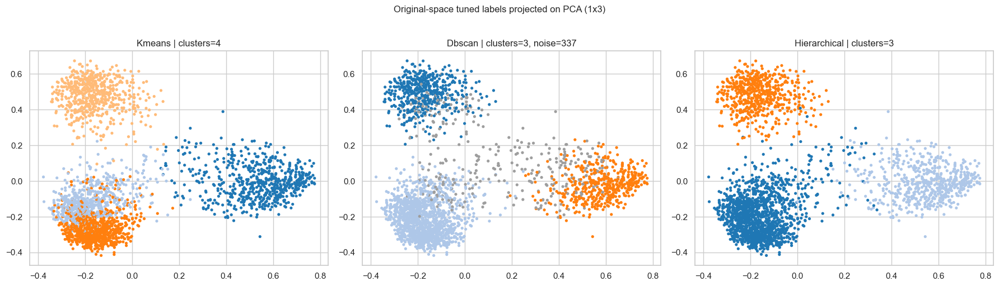

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


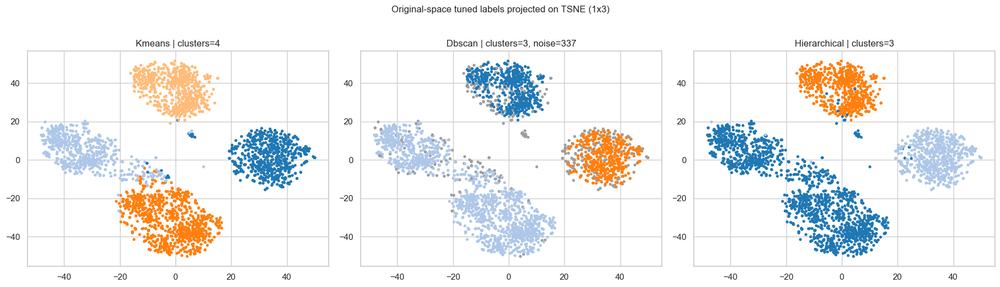

[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


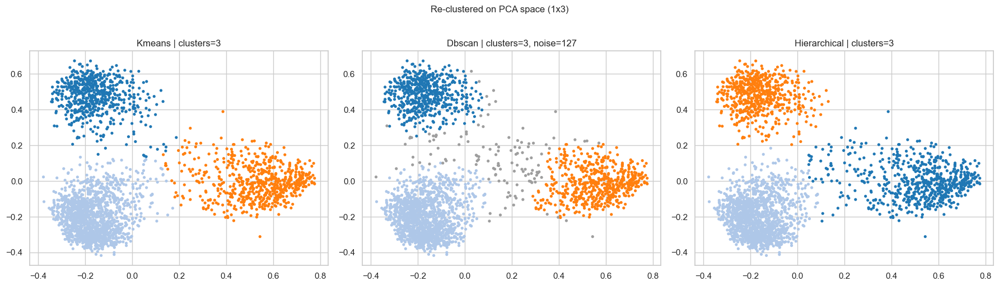

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


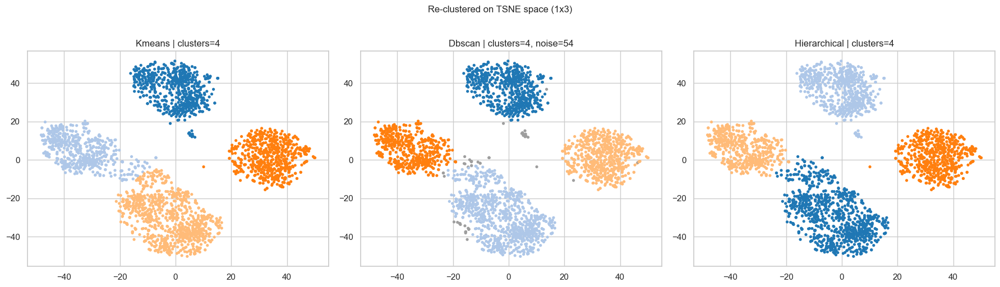

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


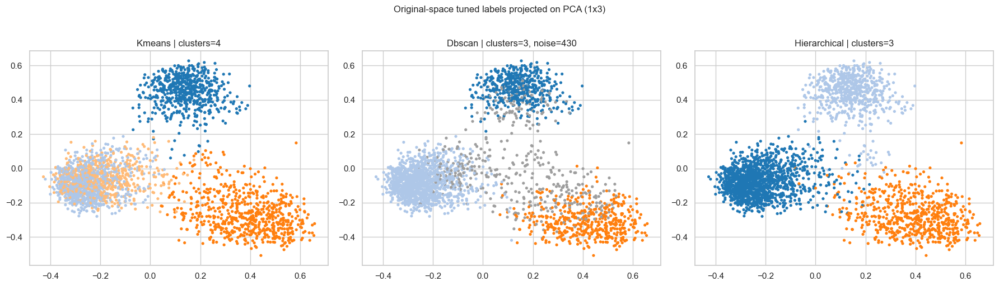

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


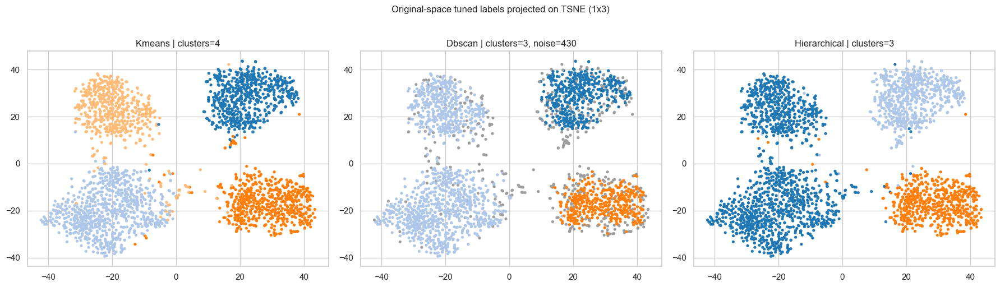

[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


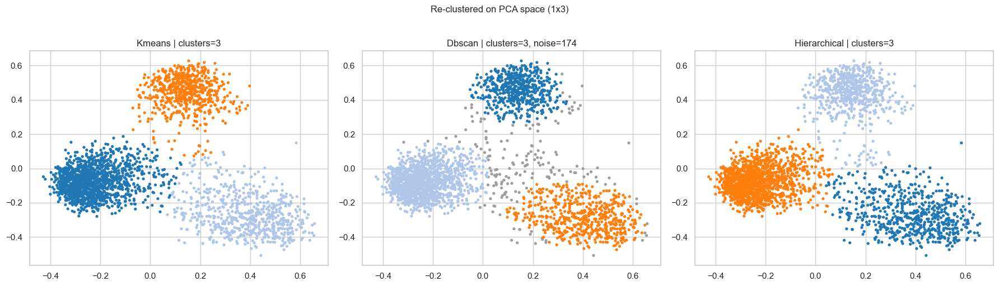

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


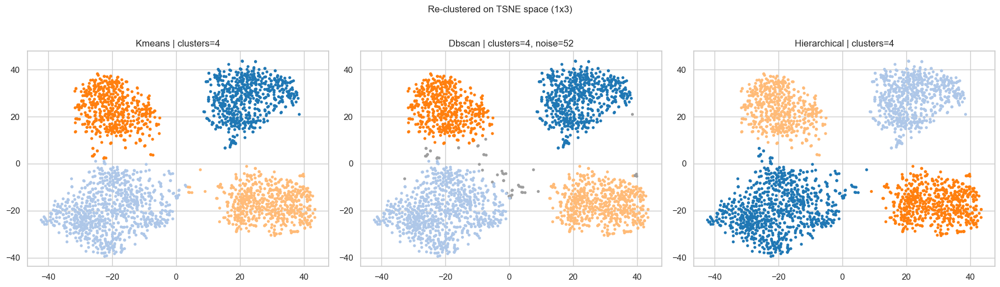

Batches:   0%|          | 0/22 [00:00<?, ?it/s]

[PLOT] kmeans: unique labels=[0, 1, 2, 3, 4]
[PLOT] dbscan: unique labels=[-1, 0, 1]
[PLOT] hierarchical: unique labels=[0, 1, 2]


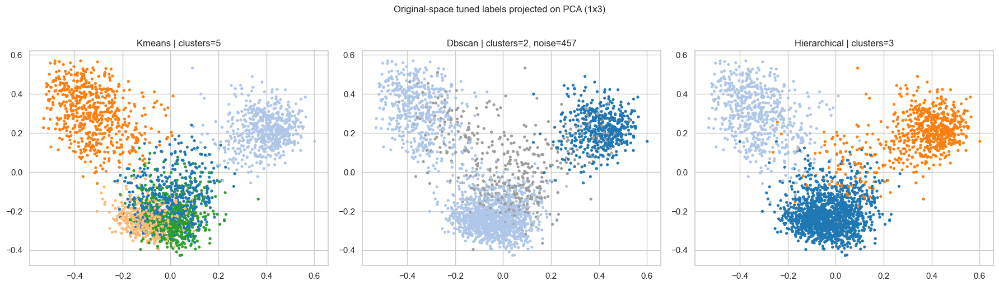

[PLOT] kmeans: unique labels=[0, 1, 2, 3, 4]
[PLOT] dbscan: unique labels=[-1, 0, 1]
[PLOT] hierarchical: unique labels=[0, 1, 2]


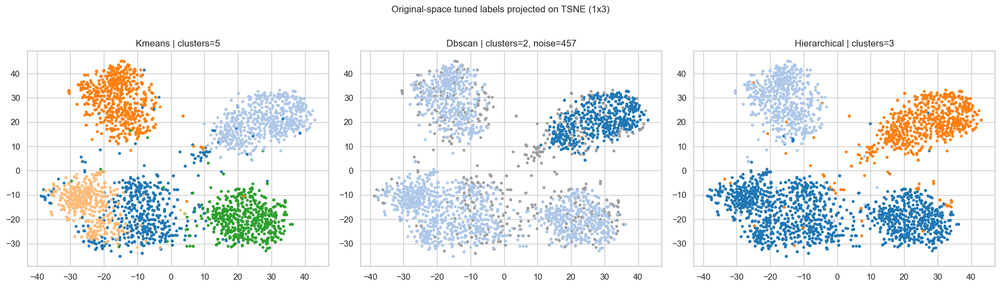

[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


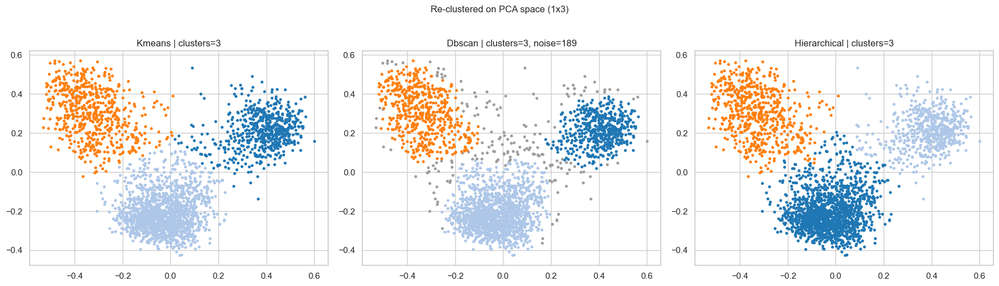

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


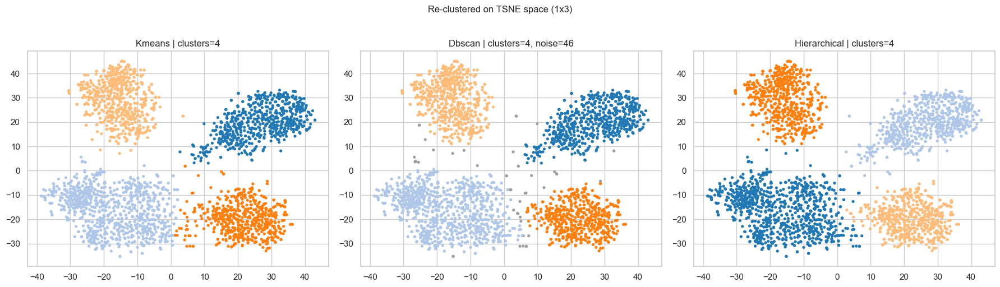

Batches:   0%|          | 0/22 [00:00<?, ?it/s]

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1]
[PLOT] hierarchical: unique labels=[0, 1, 2]


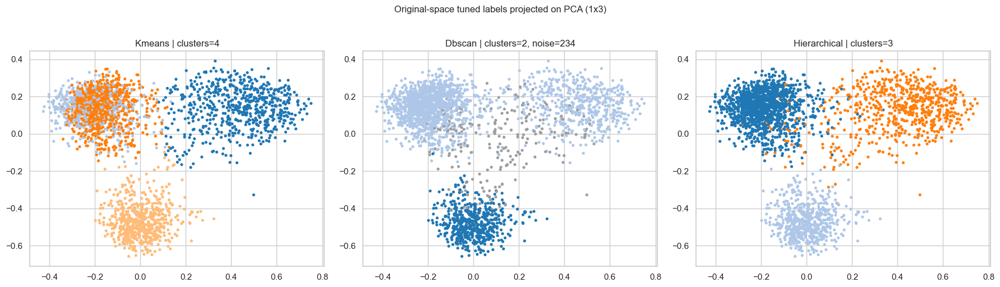

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1]
[PLOT] hierarchical: unique labels=[0, 1, 2]


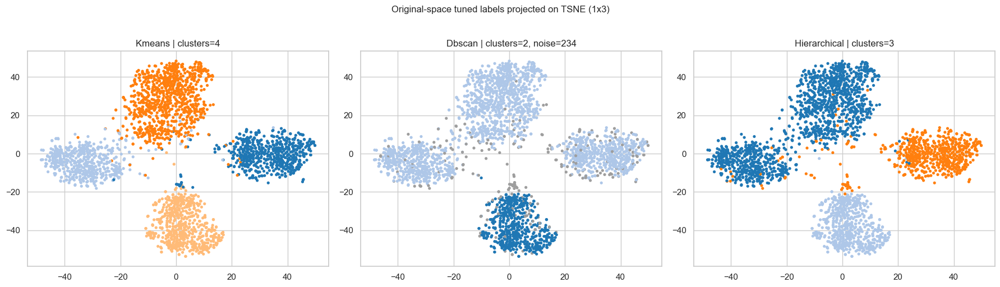

[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


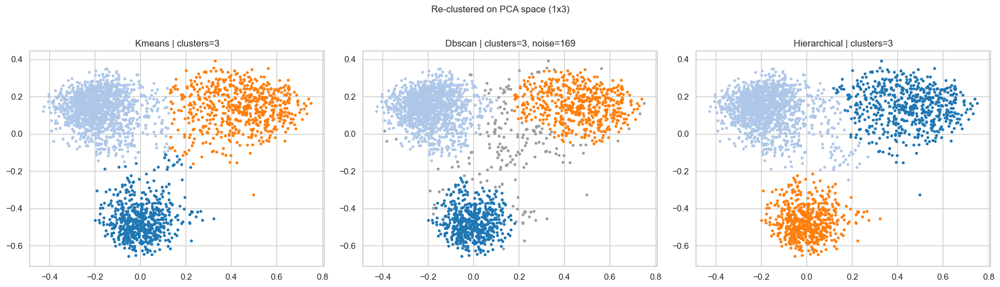

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


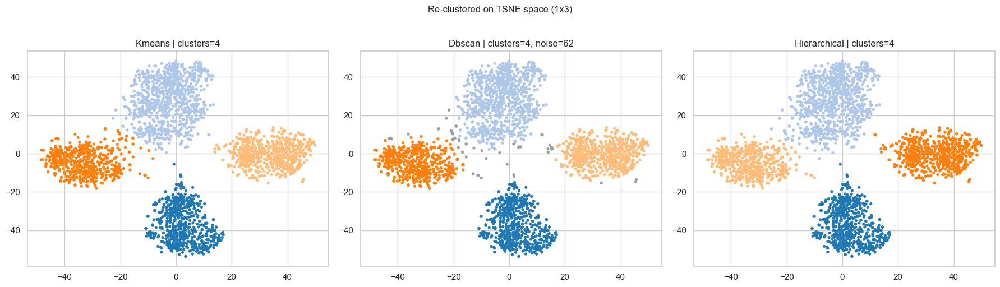

Batches:   0%|          | 0/22 [00:00<?, ?it/s]

Batches:   0%|          | 0/22 [00:00<?, ?it/s]

[PLOT] kmeans: unique labels=[0, 1, 2, 3, 4, 5]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3, 4, 5, 6]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]...


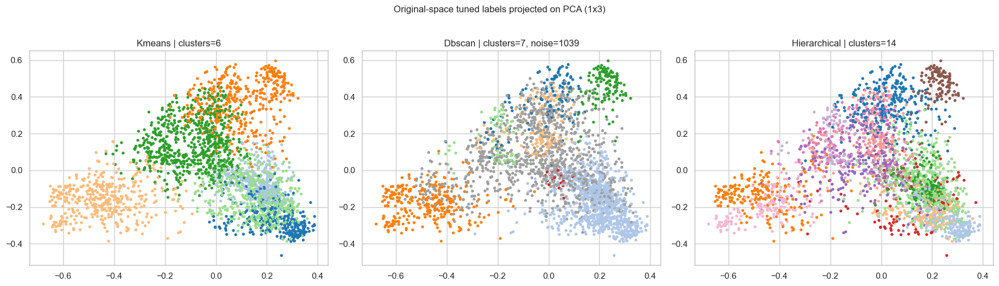

[PLOT] kmeans: unique labels=[0, 1, 2, 3, 4, 5]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3, 4, 5, 6]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]...


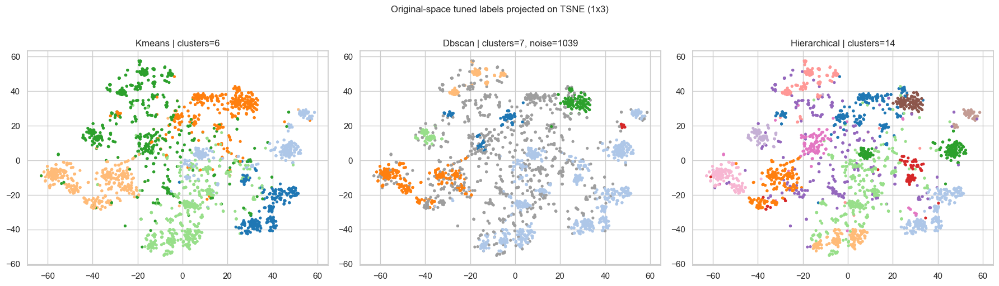

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


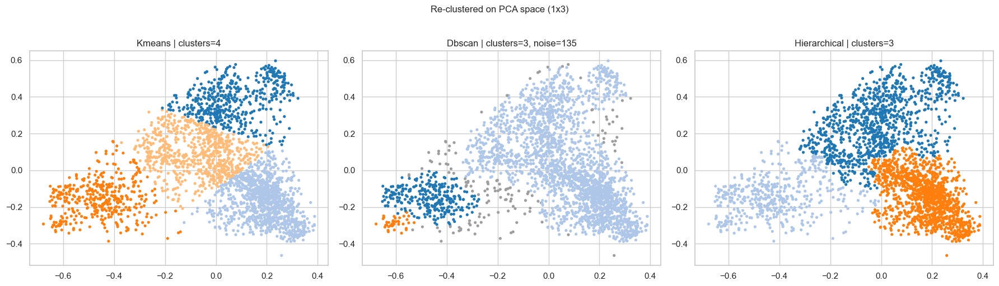

[PLOT] kmeans: unique labels=[0, 1, 2, 3, 4]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]...
[PLOT] hierarchical: unique labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


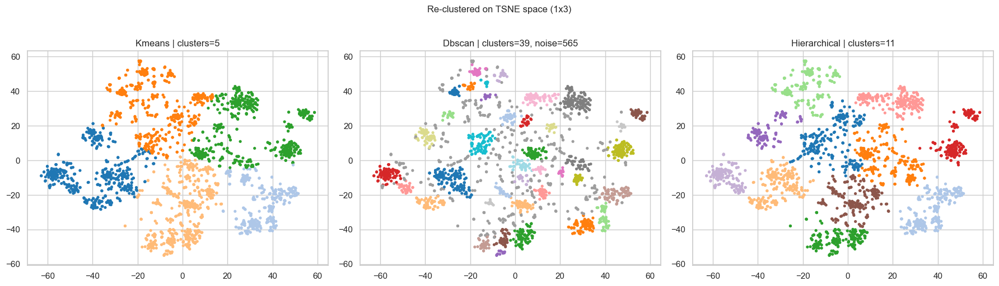

,preprocess,text_mode,algorithm,silhouette,davies_bouldin,calinski_harabasz,homogeneity_wrt_score
0,basic_clean,concat,dbscan,0.198332,1.870178,431.062702,0.028323
1,minimal,text,dbscan,0.194850,1.896059,394.511559,0.023346
2,basic_plus_stopwords,weighted,dbscan,0.175611,1.662963,132.341962,0.044383
3,basic_plus_stopwords,concat,dbscan,0.172809,2.026568,338.778978,0.029567
4,basic_stop_lemma,concat,dbscan,0.125304,2.328374,300.431979,0.012576
5,basic_stop_stem,concat,dbscan,0.120522,2.352932,265.363969,0.018586
6,basic_clean,concat,hierarchical,0.174372,2.039408,424.768220,0.019561
7,minimal,text,hierarchical,0.162409,2.141874,388.035028,0.018177
8,basic_plus_stopwords,concat,hierarchical,0.147703,2.263957,337.492241,0.018730
9,basic_stop_lemma,concat,hierarchical,0.135221,2.421879,309.995803,0.014363


In [32]:

# To answer: "Which preprocessing strategy performs better?"
trial_settings = [
    ("minimal", TextFeatureConfig(mode="text")),
    ("basic_clean", TextFeatureConfig(mode="concat")),
    ("basic_plus_stopwords", TextFeatureConfig(mode="concat")),
    ("basic_stop_stem", TextFeatureConfig(mode="concat")),
    ("basic_stop_lemma", TextFeatureConfig(mode="concat")),
    ("basic_plus_stopwords", TextFeatureConfig(mode="weighted", summary_weight=0.7, text_weight=0.3)),
]

comparison_rows = []

for prep_name, text_cfg in tqdm(trial_settings, desc="Trial configs"):
    cfg = ExperimentConfig(
        preprocess_name=prep_name,
        text_feature_cfg=text_cfg,
        sample_size=3000,
    )

    out = run_experiment(df, cfg, plot=True, verbose=False)
    for algo, m in out["metrics_original"].items():
        comparison_rows.append({
            "preprocess": prep_name,
            "text_mode": text_cfg.mode,
            "algorithm": algo,
            "silhouette": m["silhouette"],
            "davies_bouldin": m["davies_bouldin"],
            "calinski_harabasz": m["calinski_harabasz"],
            "homogeneity_wrt_score": m["homogeneity_wrt_score"],
        })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.sort_values(["algorithm", "silhouette"], ascending=[True, False]).reset_index(drop=True)


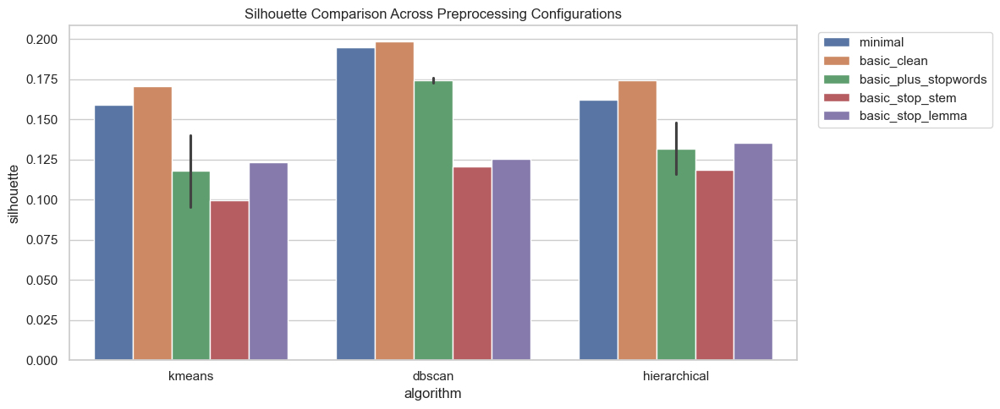

In [37]:

plt.figure(figsize=(12, 5))
sns.barplot(data=comparison_df, x="algorithm", y="silhouette", hue="preprocess")
plt.title("Silhouette Comparison Across Preprocessing Configurations")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [43]:
from IPython.display import display, Markdown
from itables import init_notebook_mode, show
import pandas as pd

init_notebook_mode(all_interactive=True)

display(Markdown("""
### Metric Guide
- **Silhouette**: higher is better  
- **Calinski-Harabasz**: higher is better  
- **Davies-Bouldin**: lower is better  
- **Homogeneity (w.r.t. Score)**: higher is better *(proxy only; Score is not ground-truth topic label)*
"""))

comparison_df = pd.DataFrame(comparison_rows)
comparison_df_sorted = comparison_df.sort_values(
    ["algorithm", "silhouette"], ascending=[True, False]
).reset_index(drop=True)

# Interactive sortable/filterable table:
show(
    comparison_df_sorted,
    pageLength=25,
    scrollX=True,
    buttons=["copy", "csv", "excel"],
    classes="display compact"
)



### Metric Guide
- **Silhouette**: higher is better  
- **Calinski-Harabasz**: higher is better  
- **Davies-Bouldin**: lower is better  
- **Homogeneity (w.r.t. Score)**: higher is better *(proxy only; Score is not ground-truth topic label)*


Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)


[PLOT] kmeans: unique labels=[0, 1, 2, 3, 4, 5, 6, 7]
[PLOT] dbscan: unique labels=[-1, 0, 1]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]...


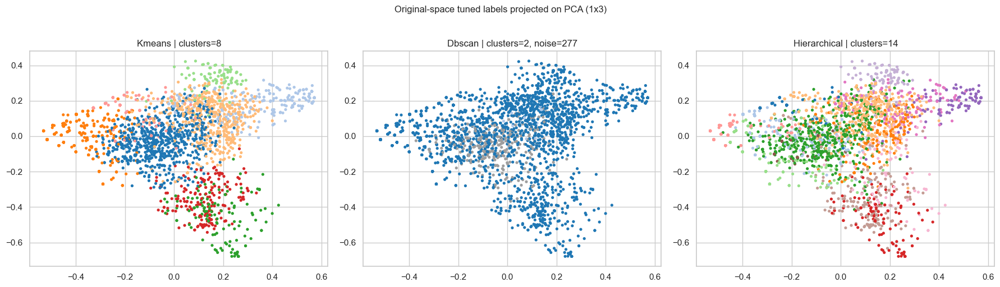

[PLOT] kmeans: unique labels=[0, 1, 2, 3, 4, 5, 6, 7]
[PLOT] dbscan: unique labels=[-1, 0, 1]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]...


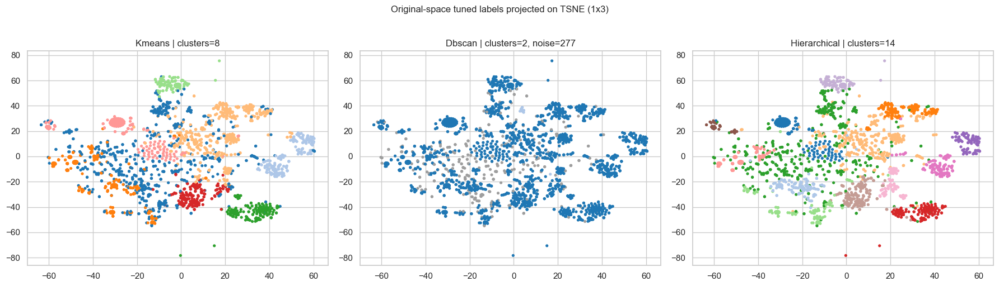

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1]
[PLOT] hierarchical: unique labels=[0, 1, 2]


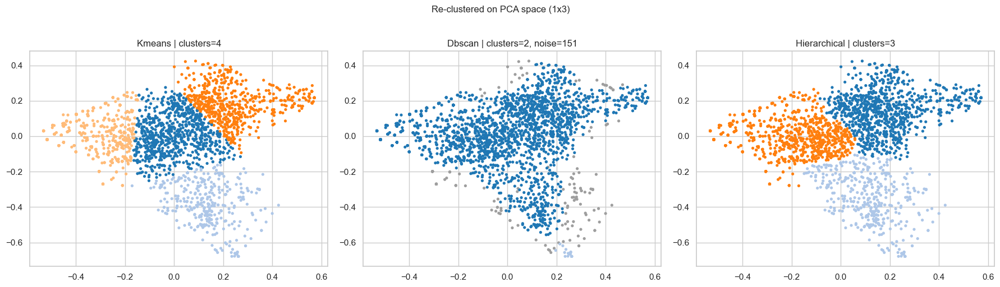

[PLOT] kmeans: unique labels=[0, 1, 2, 3, 4, 5]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]...
[PLOT] hierarchical: unique labels=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]...


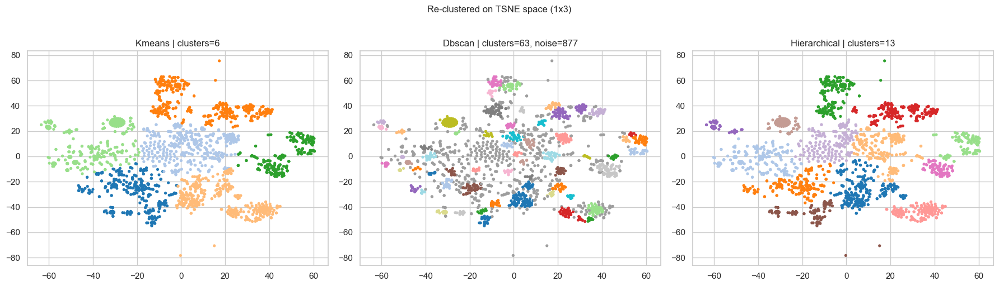

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


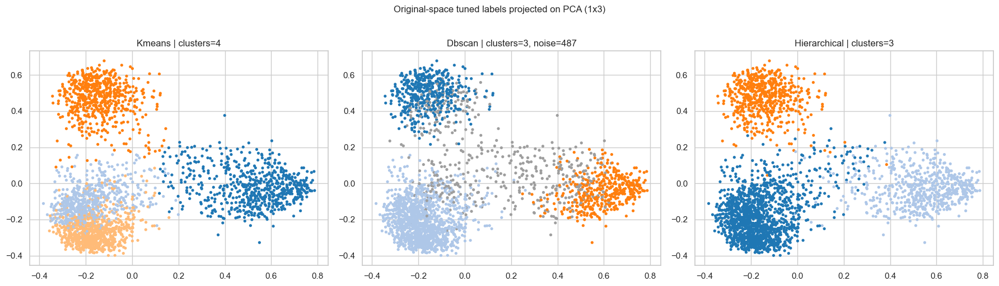

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


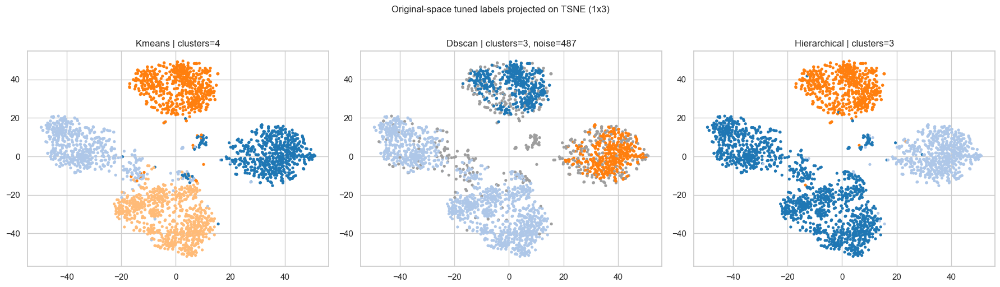

[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


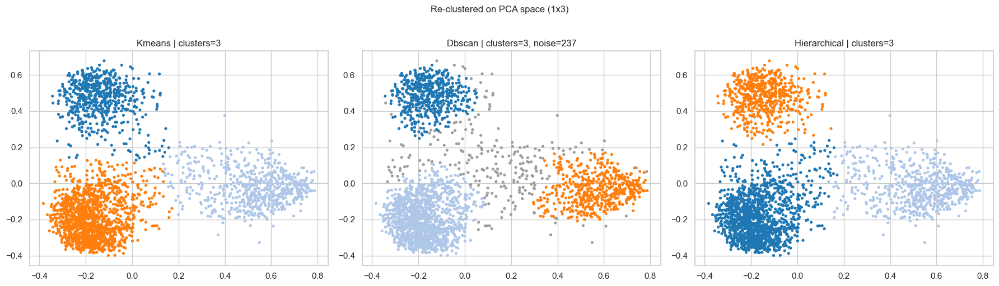

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3, 4]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


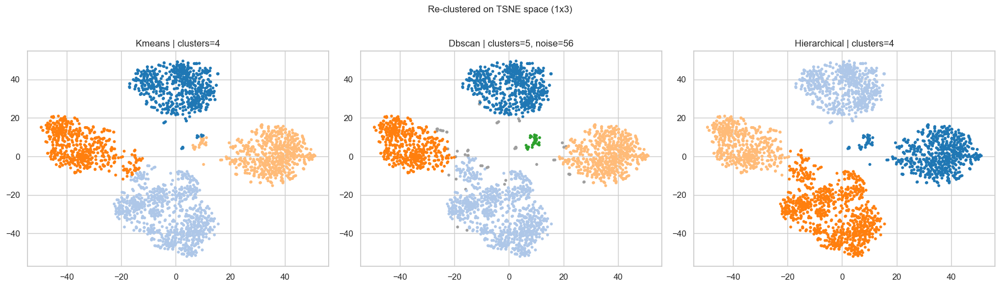

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


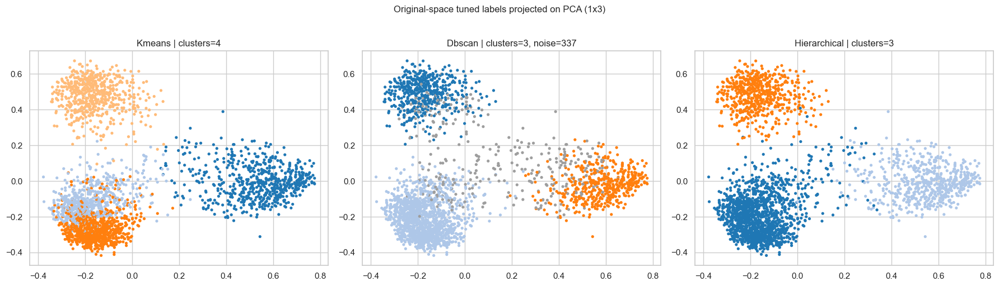

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


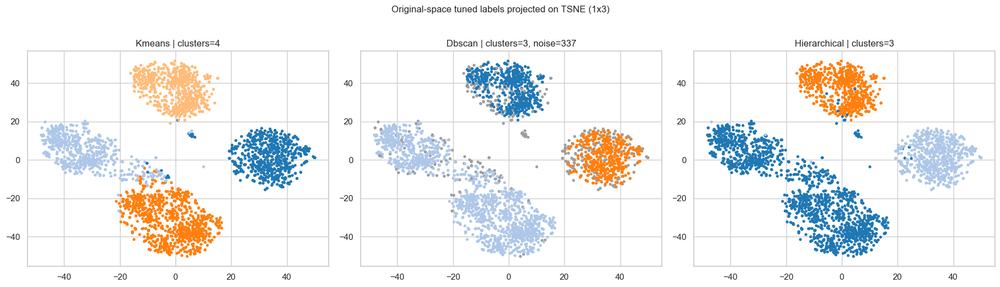

[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


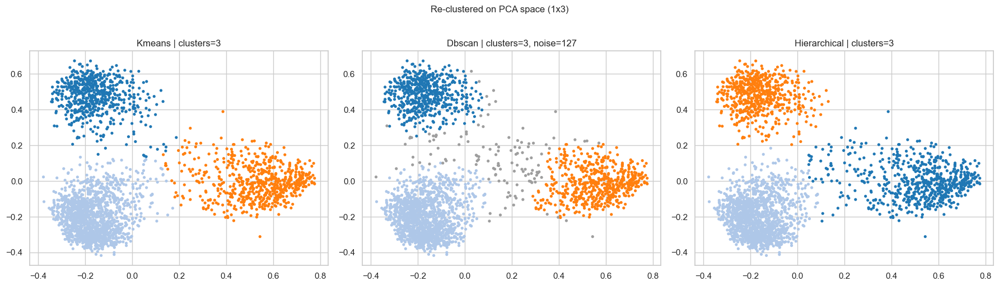

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


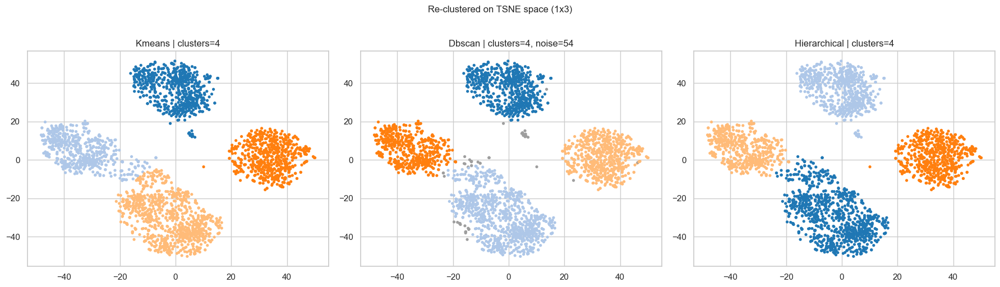

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


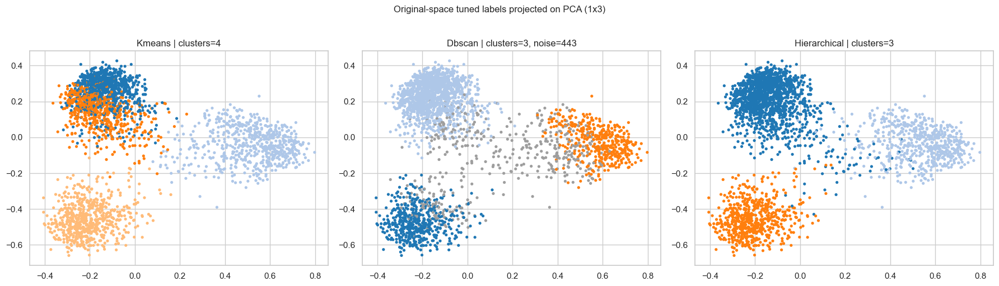

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


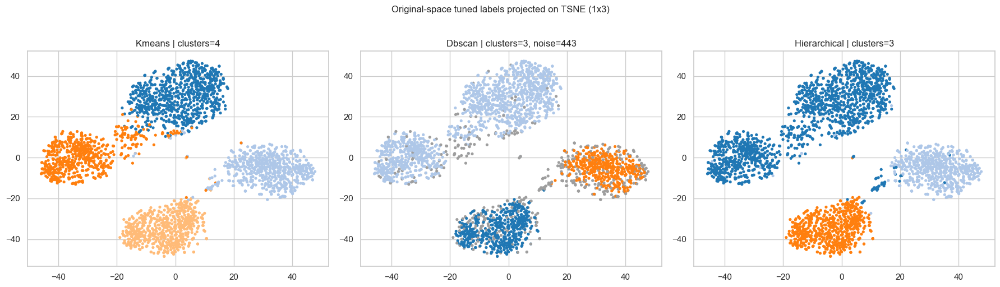

[PLOT] kmeans: unique labels=[0, 1, 2]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2]
[PLOT] hierarchical: unique labels=[0, 1, 2]


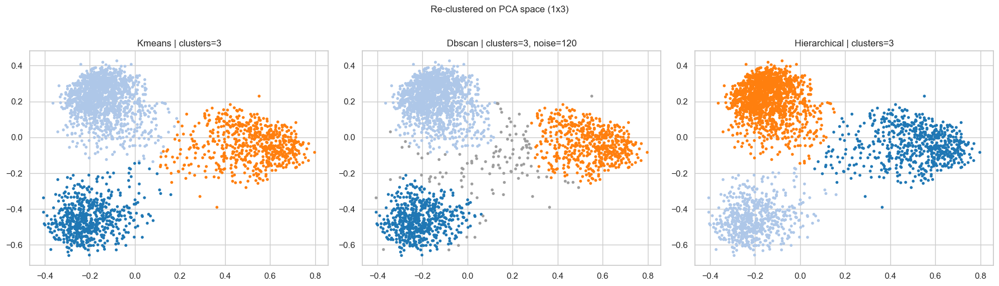

[PLOT] kmeans: unique labels=[0, 1, 2, 3]
[PLOT] dbscan: unique labels=[-1, 0, 1, 2, 3]
[PLOT] hierarchical: unique labels=[0, 1, 2, 3]


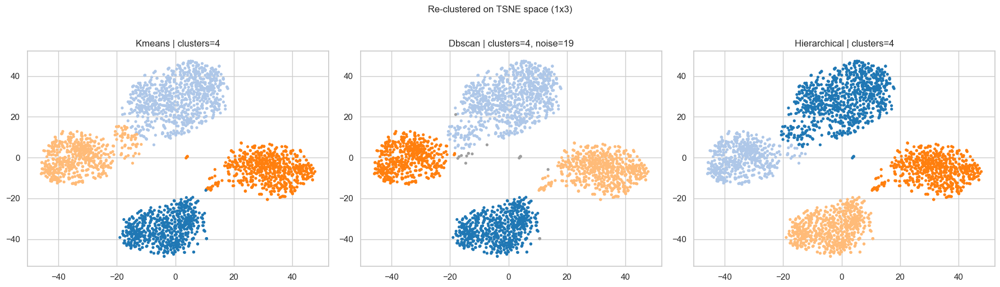

Metric guide:
- Silhouette: higher is better
- Davies-Bouldin: lower is better
- Calinski-Harabasz: higher is better
- Homogeneity_wrt_score: higher is better (proxy only)


Loading ITables v2.7.0 from the init_notebook_mode cell... (need help?)



Best mode under basic_clean (DBSCAN criterion):
preprocess               basic_clean
text_mode                   weighted
summary_weight                   0.3
text_weight                      0.7
algorithm                     dbscan
silhouette                  0.201451
davies_bouldin              1.837683
calinski_harabasz         415.054504
homogeneity_wrt_score       0.029488
Name: 0, dtype: object
[LOG] Starting experiment | preprocess=basic_clean, mode=weighted, sample_size=None
[LOG] Sampled rows: 2732
[LOG] Preprocessing done in 0.08s
[LOG] Embedding extraction started...
[LOG] Embedding cache hit.
[LOG] Embedding extraction done in 0.00s | shape=(2732, 384)
[LOG] [Original] KMeans tuning started...


KMeans elbow sweep:   0%|          | 0/13 [00:00<?, ?it/s]

[LOG] [Original] KMeans tuning done in 5.89s | best_k=4
[LOG] [Original] DBSCAN tuning started...


...

Agglomerative (ward):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (complete):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (average):   0%|          | 0/13 [00:00<?, ?it/s]

Agglomerative (single):   0%|          | 0/13 [00:00<?, ?it/s]

[LOG] [TSNE] Agglomerative tuning done in 4.23s | tested=31
[LOG] Full re-tuning on reduced spaces done in 53.79s
[LOG] Experiment finished in 173.68s

Saved: ./best_labels.csv
Rows: 2732
Best params (Original):
{'kmeans': {'k': 4}, 'dbscan': {'eps': 0.29641154408454895, 'min_samples': 19, 'metric': 'cosine'}, 'hierarchical': {'linkage': 'ward', 'k': 3}}


In [48]:
# Compare text feature modes under the best preprocessing setup (basic_clean),
# then export full-data labels for the best mode to CSV.

import pandas as pd
import numpy as np

# ---------- 1) Compare modes ----------
modes_to_test = [
    TextFeatureConfig(mode="summary"),
    TextFeatureConfig(mode="text"),
    TextFeatureConfig(mode="concat"),
    TextFeatureConfig(mode="weighted", summary_weight=0.3, text_weight=0.7), 
]

mode_rows = []
mode_results = {}

for text_cfg in modes_to_test:
    cfg = ExperimentConfig(
        preprocess_name="basic_clean",
        text_feature_cfg=text_cfg,
        sample_size=3000,
    )

    out = run_experiment(df, cfg, plot=True, verbose=False)
    mode_key = f"{text_cfg.mode}_s{getattr(text_cfg, 'summary_weight', 'na')}_t{getattr(text_cfg, 'text_weight', 'na')}"
    mode_results[mode_key] = out

    for algo, m in out["metrics_original"].items():
        mode_rows.append({
            "preprocess": "basic_clean",
            "text_mode": text_cfg.mode,
            "summary_weight": getattr(text_cfg, "summary_weight", np.nan),
            "text_weight": getattr(text_cfg, "text_weight", np.nan),
            "algorithm": algo,
            "silhouette": m.get("silhouette", np.nan),
            "davies_bouldin": m.get("davies_bouldin", np.nan),
            "calinski_harabasz": m.get("calinski_harabasz", np.nan),
            "homogeneity_wrt_score": m.get("homogeneity_wrt_score", np.nan),
        })

mode_compare_df = pd.DataFrame(mode_rows)

print("Metric guide:")
print("- Silhouette: higher is better")
print("- Davies-Bouldin: lower is better")
print("- Calinski-Harabasz: higher is better")
print("- Homogeneity_wrt_score: higher is better (proxy only)")

display(
    mode_compare_df.sort_values(
        ["algorithm", "silhouette", "davies_bouldin"],
        ascending=[True, False, True]
    ).reset_index(drop=True)
)

# ---------- 2) Pick best mode (based on DBSCAN + max Silhouette, tie -> lower DBI) ----------
dbscan_only = mode_compare_df[mode_compare_df["algorithm"] == "dbscan"].copy()
dbscan_only = dbscan_only.sort_values(
    ["silhouette", "davies_bouldin"],
    ascending=[False, True]
).reset_index(drop=True)

best_row = dbscan_only.iloc[0]
best_mode = best_row["text_mode"]
best_sw = best_row["summary_weight"]
best_tw = best_row["text_weight"]

print("\nBest mode under basic_clean (DBSCAN criterion):")
print(best_row)

# ---------- 3) Re-run best mode on FULL dataset ----------
# build best TextFeatureConfig
if best_mode == "weighted":
    best_text_cfg = TextFeatureConfig(mode="weighted", summary_weight=float(best_sw), text_weight=float(best_tw))
elif best_mode == "summary":
    best_text_cfg = TextFeatureConfig(mode="summary")
elif best_mode == "text":
    best_text_cfg = TextFeatureConfig(mode="text")
else:
    best_text_cfg = TextFeatureConfig(mode="concat")

full_cfg = ExperimentConfig(
    preprocess_name="basic_clean",
    text_feature_cfg=best_text_cfg,
    sample_size=None,   # full data
)

full_out = run_experiment(df, full_cfg, plot=False, verbose=True)

# ---------- 4) Export full-data labels ----------
export_df = full_out["work_df"][["Id", "Score", "Summary", "Text"]].copy()
export_df["kmeans_label"] = full_out["labels_original"]["kmeans"]
export_df["dbscan_label"] = full_out["labels_original"]["dbscan"]
export_df["hierarchical_label"] = full_out["labels_original"]["hierarchical"]

output_csv = "./best_labels.csv"
export_df.to_csv(output_csv, index=False, encoding="utf-8")

print(f"\nSaved: {output_csv}")
print("Rows:", len(export_df))
print("Best params (Original):")
print(full_out["best_params"]["Original"])


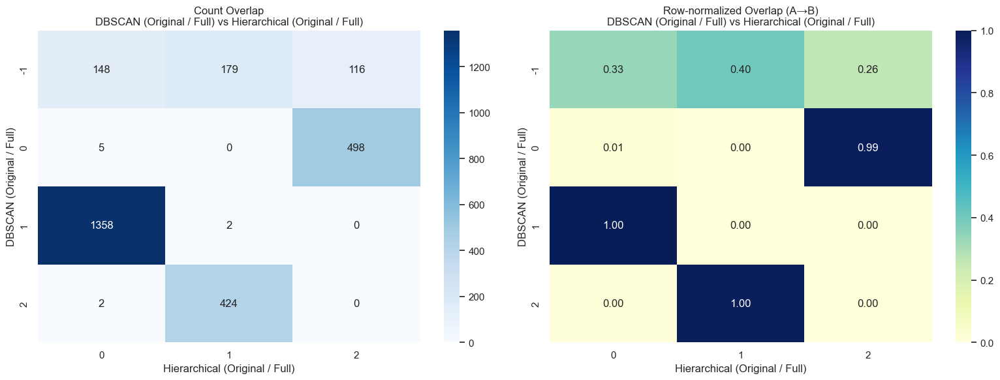

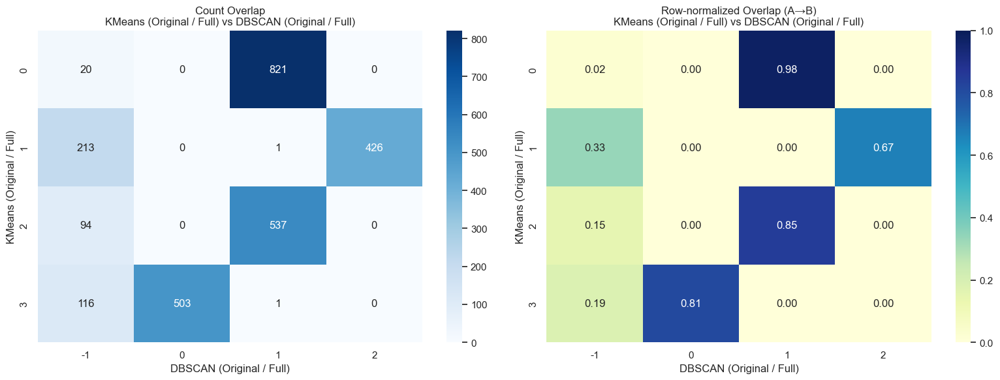

In [50]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_label_overlap_heatmaps(labels_a, labels_b, name_a, name_b, figsize=(16, 6)):
    tmp = pd.DataFrame({"A": labels_a, "B": labels_b})

    # Overlap count
    ct = pd.crosstab(tmp["A"], tmp["B"])

    # Row-normalized overlap
    ct_row = ct.div(ct.sum(axis=1), axis=0).fillna(0)

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=axes[0])
    axes[0].set_title(f"Count Overlap\n{name_a} vs {name_b}")
    axes[0].set_xlabel(name_b)
    axes[0].set_ylabel(name_a)

    sns.heatmap(ct_row, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=axes[1])
    axes[1].set_title(f"Row-normalized Overlap (A→B)\n{name_a} vs {name_b}")
    axes[1].set_xlabel(name_b)
    axes[1].set_ylabel(name_a)

    plt.tight_layout()
    plt.show()


# 1) DBSCAN vs Hierarchical
plot_label_overlap_heatmaps(
    full_out["labels_original"]["dbscan"],
    full_out["labels_original"]["hierarchical"],
    "DBSCAN (Original / Full)",
    "Hierarchical (Original / Full)"
)

# 2) KMeans vs DBSCAN (plotted below the first one)
plot_label_overlap_heatmaps(
    full_out["labels_original"]["kmeans"],
    full_out["labels_original"]["dbscan"],
    "KMeans (Original / Full)",
    "DBSCAN (Original / Full)"
)


## 12) Print At Least 4 Samples Per Cluster (with Review Id)

In [38]:

def print_cluster_samples(work_df: pd.DataFrame, labels: np.ndarray, n_per_cluster: int = 4, text_col: str = "Text"):
    temp = work_df[["Id", "Score", "Summary", "Text"]].copy()
    temp["cluster"] = labels

    rows = []
    for cid in sorted(temp["cluster"].unique()):
        sub = temp[temp["cluster"] == cid].head(n_per_cluster)
        for _, row in sub.iterrows():
            rows.append({
                "cluster_id": cid,
                "Id": int(row["Id"]) if pd.notnull(row["Id"]) else "NA",
                "Score": row["Score"],
                "Summary": str(row["Summary"])[:180],
                "Text": (str(row[text_col])[:350] + "...") if len(str(row[text_col])) > 350 else str(row[text_col]),
            })

    out_df = pd.DataFrame(rows, columns=["cluster_id", "Id", "Score", "Summary", "Text"])

    pd.set_option("display.max_rows", None)
    pd.set_option("display.max_colwidth", None)
    pd.set_option("display.width", None)

    display(out_df)
    return out_df

print("KMeans samples")
_ = print_cluster_samples(results["work_df"], results["labels_original"]["kmeans"], n_per_cluster=4)


KMeans samples


,cluster_id,Id,Score,Summary,Text
0,0,329849,5,My Pooch loves them,"Since my pet does not like having his teeth cleaned, I have been giving him greenies for the past six years. Each vet check-up confirms that he has no plaque buildup. He is a picky eater but loves the taste of them as well."
1,0,329946,5,great product,"I was amazed at how well these cleaned my dogs teeth. He is not happy with getting his teeth brushed, especially in the back, the Greenies have assisted with cleaning this hard to reach area. I have read other reviews where people have had trouble with their dogs trying to chew off too much and choking or what-ever - my solution stay with your dog ..."
2,0,329791,5,Great product for your dog !,"Have used greenies since they came out and they definitely help keep your dog's teeth clean. My dog gets excited about being treated to a Greenie everyday. The pricing was very attractive through Amazon, as much as half of what you would pay at a pet store. Very impressed with the product."
3,0,330034,5,Great treat for you dog while improving their tooth health,"Greenies are a great product that dogs love and while they are enjoying their daily treat, they are actually keeping their teeth and gums clean. I always share the information on Greenies when people ask how I keep my 6 year old Yellow Labradors teeth so clean. I'd always thought they were a bit expensive but Amazon has brought them to us at a m..."
4,1,563717,5,Quaker soft baked oatmeal cookie,"I rec'd this product from influenster and Quaker for testing purposes. I've always enjoyed Quaker oats from the hot oatmeal, down to the cookie itself. Quaker soft baked oatmeal cookie is made with whole grain Quaker oats, At least 10 grams of whole grains per serving.<br />Made with real fruit, Good source of fiber, delicious. Quaker oats been aro..."
5,1,563247,5,Soft Baked cookies,These cookies are so good and soft.. I love these cookies eat atleast one everyday I find littles one's love them as well.. You can't go wrong with these cookies plus they are good for you..
6,1,563847,2,~~meh~~,Let me start off by saying I'm a bit of a cookie snob having lived next door to my grandmother for most of my youth. There's nothing better than a homemade cookie. Having tried these and shared them with some co-workers I can honestly say that it's not just me that wasn't impressed. There wasn't much said that was positive. For being a soft bak...
7,1,563174,3,Not tasty,I dont like how it tastes because i don't like oatmeal or raisins but if you like them then i think its good to eat these cookies because they're healthy and you will probably like the taste.
8,2,367936,5,frhgthyrfedws yeyeyey,"I really like this oil. Its amazing. I use it for my hair, and skin, and omfg. The first treatment I did to my hair, made it silky soft, shiny, and, it was not frizzy. Thank teh lard. And I used it on my gigantic pimple, the first 10 minutes, the redness from my pimple went away, and overnight, my pimple shrunk a decent amount. I havent consumed th..."
9,2,367735,5,The best there is...,"I have been using coconut oil as a body/face/hair moisturizer for about a year now and it has made all the difference in the world for my health. After doing a bit of research, I chose this product in particular due to the description, reviews, pricepoint, and the fact that it is a brand I have seen in many stores and am familiar with.<br /><br />T..."



## 13) Hierarchical Heatmap + Dendrogram

Heatmap and dendrogram are complementary visualization tools:
- A heatmap shows pairwise similarity/distance patterns as a matrix.
- A dendrogram shows the hierarchical merge structure of clusters.


Suggested cut level (largest vertical gap): 4.7714
Estimated clusters at suggested cut: 4


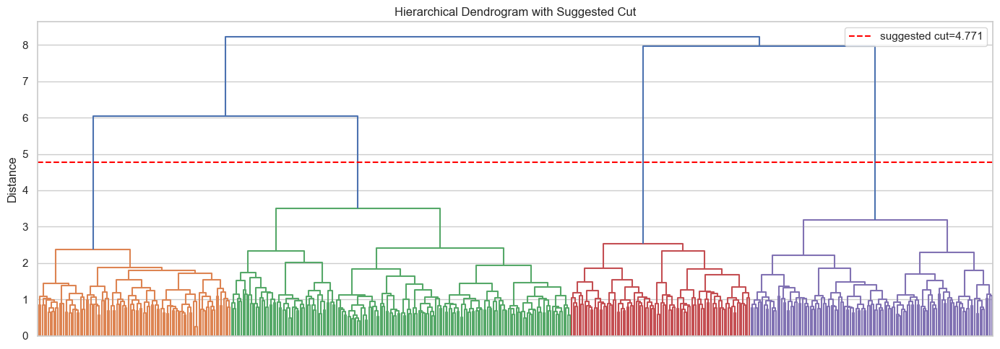

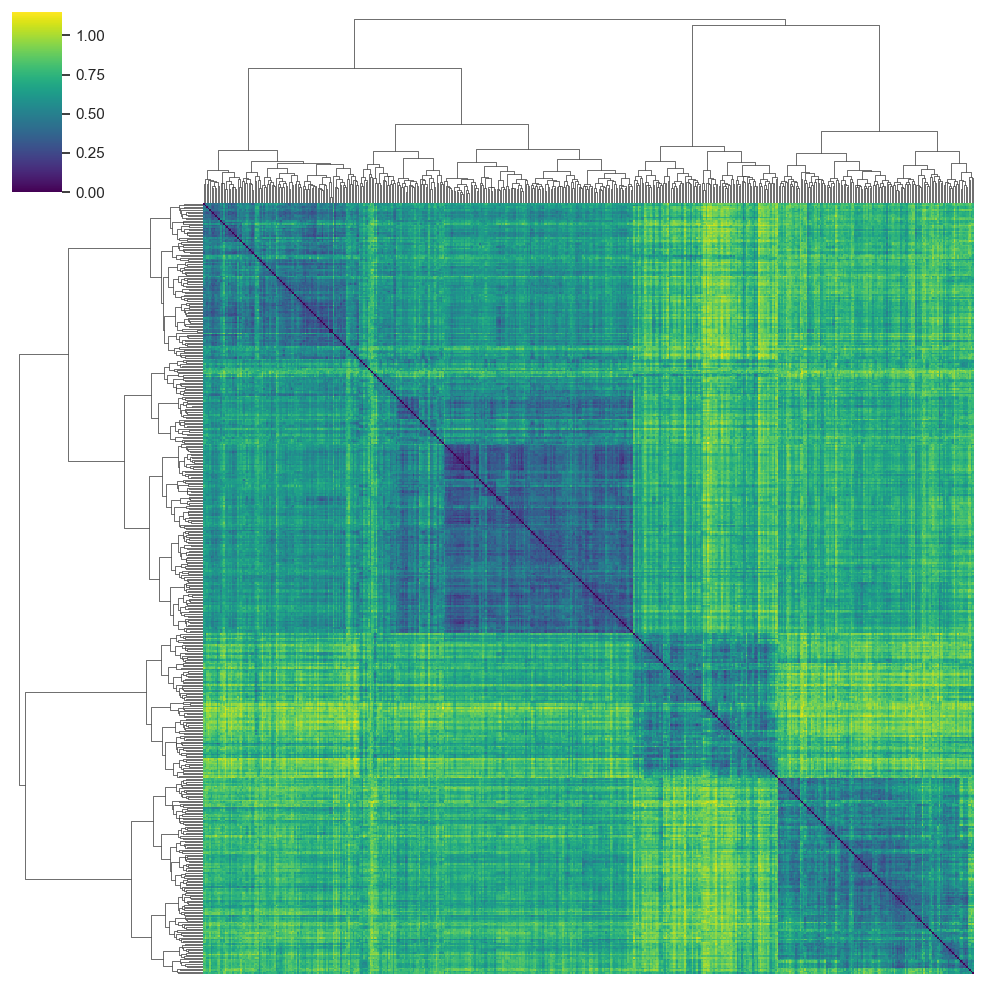

In [36]:

def suggest_cut_from_linkage(Z: np.ndarray) -> float:
    """Suggest a cut level based on the largest vertical gap between merge distances."""
    d = Z[:, 2]
    if len(d) < 2:
        return float(d[-1]) if len(d) else 0.0
    gaps = np.diff(d)
    idx = int(np.argmax(gaps))
    cut = float((d[idx] + d[idx + 1]) / 2.0)
    return cut


subset_n = 500
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(results["embeddings"].shape[0], size=min(subset_n, results["embeddings"].shape[0]), replace=False)
X_sub = results["embeddings"][idx]

Z = linkage(X_sub, method="ward")
cut_level = suggest_cut_from_linkage(Z)
cluster_labels_cut = fcluster(Z, t=cut_level, criterion="distance")

print(f"Suggested cut level (largest vertical gap): {cut_level:.4f}")
print(f"Estimated clusters at suggested cut: {len(np.unique(cluster_labels_cut))}")

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=cut_level)
plt.axhline(cut_level, color="red", linestyle="--", label=f"suggested cut={cut_level:.3f}")
plt.title("Hierarchical Dendrogram with Suggested Cut")
plt.ylabel("Distance")
plt.legend()
plt.tight_layout()
plt.show()

# Heatmap + Dendrogram (clustermap)
# For size/speed control, we visualize a subset.
# Consistency note: cosine distance is used here to align with embedding-style clustering settings.
D = squareform(pdist(X_sub, metric="cosine"))
D_df = pd.DataFrame(D)

sns.clustermap(
    D_df,
    row_linkage=Z,
    col_linkage=Z,
    cmap="viridis",
    figsize=(10, 10),
    xticklabels=False,
    yticklabels=False,
)
plt.show()


# Questions

## Section 1 — Preprocessing and Feature Extraction

### 1) Which preprocessing method or combination of methods achieved better performance?

Several input construction strategies were compared: `summary`, `text`, `concat`, and `weighted`.

The clearest pattern in the results was that the way the input text was constructed had a stronger impact than minor cleaning differences.

Under the `basic_clean` preprocessing configuration, results on the original embedding space showed the following:

- **DBSCAN** performed best overall.
- Within DBSCAN, the best performance was achieved by the **weighted** mode.
- The strongest configuration used approximately **0.7 weight for Text and 0.3 weight for Summary**, with a silhouette score around **0.20**.
- `concat` and `text` performed very similarly and slightly below weighted.
- `summary` alone performed significantly worse (silhouette around **0.06**).

This outcome is logically consistent with the structure of the dataset.

The `Text` field contains detailed semantic context and richer information.  
The `Summary` field is short, user-written, and often noisy or generic.  
Because of this, relying heavily on `Summary` weakens the representation.

When most of the weight is placed on `Text` and only a small portion is taken from `Summary`, embeddings become more stable and clustering improves.

Therefore, the best-performing configuration was:

**basic_clean + weighted input (0.7 Text, 0.3 Summary) + DBSCAN in original embedding space**

---

### 2) Why is preprocessing necessary for textual data?

Text data is inherently inconsistent.  
Two reviews may express the same idea but differ in casing, punctuation, formatting, or redundant stop-words.

Without preprocessing:

- Surface variations introduce unnecessary noise.
- Embedding representations become less stable.
- Clusters become less coherent.

Preprocessing reduces superficial variation and enforces consistency.  
When textual input is more consistent, embeddings better reflect semantic similarity.  
As a result, clustering quality improves.

---

### 3) Explain the difference between Stemming and Lemmatization, and discuss the advantages and disadvantages of each.

Stemming reduces words to crude roots using simple heuristic rules.  
It is fast but may produce non-valid words and can collapse distinct terms incorrectly.

Lemmatization reduces words to proper dictionary forms using linguistic rules.  
It is more accurate but computationally heavier.

In transformer-based pipelines, aggressive stemming is often less critical because contextual embeddings already encode morphological information.  
Over-normalization may even remove useful signals.

---

### 4) Why is feature extraction necessary? Why can raw text not be used directly for clustering?

Clustering algorithms operate in numerical vector space.  
Raw text does not have fixed dimensionality or a meaningful geometric structure.

Feature extraction transforms each review into a fixed-length vector representation.  
Embeddings map semantically similar texts to nearby points in vector space.

Without this transformation, distance-based clustering is not mathematically possible.

---

## Section 2 — Problem Solving Process

### 1) Explain Supervised Learning and Unsupervised Learning, and compare them.

Supervised learning uses labeled data to learn a mapping from inputs to known outputs.  
Evaluation is straightforward because true labels exist.

Unsupervised learning does not rely on labeled targets.  
Its goal is to uncover latent structure, such as clusters.

This project is unsupervised because no ground-truth topic labels exist for the reviews.  
Only proxy variables like rating score are available.

---

### 2) Why are feature vectors (Embeddings) used? What characteristics do they contain?

Embeddings convert text into dense numerical vectors that encode semantic meaning.  
They capture contextual relationships, topic similarity, and partial sentiment information.

Because clustering relies on distances between vectors, embeddings provide the geometric structure necessary for grouping semantically related reviews.

---

### 3) Compare Bag of Words, TF-IDF, Word Embeddings, and Sentence Embeddings in terms of semantic quality.

Bag of Words represents documents by raw word counts.  
It ignores word order and meaning.

TF-IDF improves upon Bag of Words by reweighting terms according to global frequency.  
However, it still does not encode true semantics.

Word Embeddings assign dense vectors to individual words, capturing semantic similarity at token level.  
However, full document meaning must be aggregated.

Sentence Embeddings directly represent full sentences or paragraphs.  
They encode contextual meaning and are therefore better suited for semantic clustering tasks.

For review clustering, sentence embeddings provide the highest semantic fidelity.

---

### 4) Explain Sentence Transformer models and specifically the all-MiniLM-L6-v2 model.

Sentence Transformers are models trained to produce semantically meaningful sentence-level embeddings.  
They are optimized so that semantically similar sentences lie close in vector space.

The `all-MiniLM-L6-v2` model is a lightweight transformer that outputs 384-dimensional embeddings.  
It offers a good balance between speed and semantic quality, making it suitable for large review datasets.

---

### 5) What is the Elbow Method, and how is it used in K-Means?

K-Means requires selecting the number of clusters, K.

The Elbow Method runs K-Means for multiple values of K and plots clustering cost (inertia).  
As K increases, cost decreases.  
The optimal K is typically near the “elbow”, where further improvements become marginal.

This approach helps balance model simplicity and cluster compactness.

---

### 6) Explain the clustering methods used.

K-Means partitions all points into K clusters and assumes spherical structure.  
It assigns every point to a cluster and does not handle noise explicitly.

Agglomerative clustering builds a hierarchical merge tree and requires a cut level.  
Like K-Means, it forces every point into some cluster.

DBSCAN groups points based on density and can mark sparse points as noise.  
This makes it robust in datasets containing irrelevant or ambiguous samples.

---

## Section 3 — Dimensionality Reduction

### 1) Explain how PCA works.

PCA identifies directions of maximum variance in high-dimensional space.  
It projects data onto a lower-dimensional subspace spanned by the top principal components.

PCA preserves global linear structure but cannot model nonlinear geometry.

---

### 2) Compare the performance of PCA and t-SNE.

PCA produced stable, interpretable 2D projections that preserved general structure.

t-SNE generated visually separated clusters, but it distorts global distances.  
Clustering after t-SNE sometimes showed inflated metric values because the geometry is altered.

Therefore, PCA is more reliable for analytical comparison.  
t-SNE is better suited for visualization and exploratory inspection.

---

## Section 4 — Evaluation and Analysis of Results

### 1) Introduce clustering evaluation metrics.

Silhouette measures how close a point is to its own cluster compared to neighboring clusters.  
Higher values indicate better separation and cohesion.

Davies–Bouldin measures average cluster similarity.  
Lower values are better.

Calinski–Harabasz compares between-cluster variance to within-cluster variance.  
Higher values are better.

---

### 2) Use Silhouette and Homogeneity. If inappropriate, explain why.

Silhouette is appropriate because it does not require true labels.

Homogeneity assumes ground-truth labels.  
In this dataset, no true topic labels exist.  
Rating `Score` was used as a proxy label only to test the evaluation framework.

Therefore, homogeneity is reported but not treated as definitive evidence of clustering quality.

---

### 3) Report metric values and analyze results.

Under `basic_clean` in the original embedding space:

**DBSCAN (best weighted mode):**
- Silhouette ≈ 0.20  
- Lower DB index  
- Higher CH index  

`concat` and `text` were slightly below.  
`summary` was clearly weaker.

Agglomerative and K-Means produced lower silhouette values overall.

This pattern suggests that DBSCAN handles noisy reviews better.  
Because K-Means and Agglomerative force assignment, outliers reduce cohesion.

---

### 4) Compare results before and after dimensionality reduction.

Clustering in original embedding space produced more realistic evaluations.

After PCA and t-SNE, silhouette sometimes increased, especially with DBSCAN.  
However, reduced spaces alter geometry.

Thus, clustering performance should primarily be judged in original embedding space, while reduced-space plots are useful for visualization.

---

### 5) Which clustering method performed better and why?

DBSCAN performed best overall.

The dataset contains real noise, such as short generic reviews and mixed-topic texts.  
Methods that force assignment (K-Means, Agglomerative) cannot isolate noise.  
DBSCAN can discard ambiguous points.

Because noise is removed, clusters become more coherent and internal metrics improve.

Therefore, DBSCAN is the most suitable clustering method for this dataset.
